# Olomouc green infrastructure siting: fuzzy normalisation on H3

This notebook prepares the **green-highlighted indicators** of the Olomouc GI suitability framework for an
**INFORM-style index**. It:

1. builds an **H3 hexagon grid** over the Olomouc microzones,
2. moves every input dataset onto the hexes (rasters, points, lines, polygons, microzone tables),
3. normalises each indicator to **0-1 with fuzzy membership functions**,
4. combines indicators into **components** and **dimensions**, ready for weighting in the web portal,
5. exports one table keyed by `h3_index` (CSV, GeoPackage, GeoJSON) plus a metadata file.

### Indicators covered (green rows of the framework)

| Dimension | Component | Indicator(s) in this notebook | Source |
|---|---|---|---|
| Hazard & Exposure | Urban heat | `lst_copernicus` (Landsat 45%), `heatwave_tmin` (30%), `lst_microzone` (15%), `heatwave_tmax` (10%) | Landsat LST summer 2026, Citiq heatwave rasters (8 stations), microzone `Termal_MEA` |
| Hazard & Exposure | Exposure (people) | `res_density`, `day_density` | Microzone population (dasymetric), Vodafone hourly presence or UP proxy, Kam dojíždíme for calibration |
| Vulnerability | Sensitive groups and facilities | `share_65plus`, `share_75plus`, `share_0_4`, `sensitive_facilities` | Microzone age groups `obyv_vek_*`, kindergartens `PocetMS`, primary schools `PocetZS`, doctors `PocetLekar` |
| Green Deficit | Green supply | `green_share`, `tree_cover`, `green_per_capita`, `sealing` | Urban Atlas 2021 green classes (or microzone land cover), Copernicus Tree Cover Density 10 m (or microzone `TreeCoverD`), Copernicus Imperviousness Density (optional) |
| Green Deficit | Access to green | `dist_green` | Network distance on Open Transport Map / OSM roads, H3 grid distance as fallback |
| Feasibility | Opportunity land | `brownfield_share`, `vacant_share`, `parking`, `municipal_share`, `public_building_share` | City brownfields, Urban Atlas vacant land and construction sites, parking occupancy or microzone `PocetParkM`, city-owned land |
| Feasibility | Constraints | `constraint_share` (multiplier) | Urban Atlas railways, fast transit roads, airport, water |
| Feasibility | Linear corridors | `cycle_density`, `street_density` | City cycle paths or microzone `Cyklostezk`, OSM roads or microzone `Chodniky_k` |
| Feasibility | Buildings (optional) | `up_energy` | UP energy consumption by building |

Orange rows of the framework (flooding, traffic pollution, cost, constraints) are **not** computed here.
Section 7 shows where to plug them in.

### How the index is assembled

```
mu_i          = fuzzy membership of indicator i                     (0-1, 1 = more need / more opportunity)
component     = weighted mean of its mu_i (missing inputs dropped, weights renormalised)
Heat_E        = heat^a * exposure^(1-a)                              (INFORM: hazard only counts where people are)
Green deficit = weighted mean(green supply deficit, access deficit)
Feasibility   = weighted fuzzy OR(opportunity land, corridors, buildings) x (1 - constraint share)
Vulnerability = weighted mean(share 65+, share 75+, share 0-4, sensitive facilities)
GI Need       = Heat_E^w1 * Vulnerability^w2 * GreenDeficit^w3
GI Priority   = GI Need * Feasibility
```

### Requirements

The first code cell installs everything needed:

```
pip install geopandas "h3>=4" rasterio pyproj scipy networkx matplotlib
```

**How to run:** edit the configuration cell (section 1), then run all cells. Every input except the microzones is
optional. When a layer is missing, the notebook falls back to the matching microzone column or skips the indicator,
and prints what it did.

## 0. Setup: install packages and connect to Google Drive

Run these two cells first. The second one asks for permission to access your Google Drive, then lists the files in
the data folder so you can check the exact file names before editing the configuration.

In [ ]:
%pip install -q geopandas "h3>=4" rasterio pyproj scipy networkx matplotlib

In [ ]:
from pathlib import Path
import os

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab: set DATA in the configuration to your local data folder")

DATA_DRIVE = Path("/content/drive/MyDrive/hackathon-upol/data")
if DATA_DRIVE.exists():
    print(f"Files in {DATA_DRIVE}:")
    for f in sorted(os.listdir(DATA_DRIVE)):
        print("  ", f)
else:
    print(f"Folder not found: {DATA_DRIVE}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files in /content/drive/MyDrive/hackathon-upol/data:
   .ipynb_checkpoints
   17447.zip
   HWmax_T_C.tif
   HWmin_T_C.tif
   LST_landsat_microzone_EPSG5514.tif
   NDVI_microzone_EPSG5514.tif
   SPU_BPEJ_KRAJ_124_2026-10-30_SHP.zip
   UrbanAtlas2021_microzone_EPSG5514.geojson
   brownfield.zip
   brownfields_mz.geojson
   buildings_with_class.geojson
   copernicusTreeCoverDensity10m.tif
   cycle_path.geojson
   microzones.geojson
   olomoucky_kraj.parquet
   olumouc2024_imperviousness.tiff
   olumouc2024_imperviousness_nodata.tif
   pocitova-teplotni-mapa-olomouce-2.geojson
   roads.geojson
   weatherStation_Temp_heatIDX_humidity.zip


In [ ]:
import json, math, warnings, datetime
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import h3
from shapely.geometry import Polygon, Point
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200, "display.max_columns", 40)
print("geopandas", gpd.__version__, "| h3", h3.__version__)
assert int(h3.__version__.split(".")[0]) >= 4, "This notebook uses the h3 v4 API (pip install 'h3>=4')"

geopandas 1.2.0 | h3 4.5.1


## 1. Configuration

Everything you need to change is in this cell.

* **Paths:** set a layer to `None` if you don't have it. Any format GeoPandas reads works (GeoJSON, SHP, GPKG, FileGDB with `layer`).
  Tables can be CSV or XLSX.
* **Column names:** the defaults match the microzone file supplied (`Termal_MEA`, `PopGrid_No`, ...). Check the
  columns of your other files and adjust.
* **CRS:** all area and distance work happens in **S-JTSK / Krovak East North (EPSG:5514)**. H3 works in WGS84 internally.

#### Copernicus LST
Use a **GeoTIFF** of land surface temperature, e.g. a median of clear-sky summer daytime **Sentinel-3 SLSTR LST** scenes
exported from the Copernicus Data Space Ecosystem (Browser / openEO), clipped to Olomouc. The notebook:
* converts Kelvin to Celsius automatically (if the median value is above 200),
* applies `scale` / `offset` if your product stores scaled integers,
* detects that the pixels (~1 km) are much larger than the hexagons and **bilinearly interpolates** at hex centres,
  instead of giving every hex inside a pixel the same value. Finer rasters (e.g. 30 m) are averaged per hex instead.

Because 1 km LST is coarse for a city, the microzone thermal mean (`Termal_MEA`) is kept as a second heat indicator.
Adjust their weights in section 5.

In [ ]:
DATA = Path("/content/drive/MyDrive/hackathon-upol/data")      # your Drive data folder
OUT = Path("/content/drive/MyDrive/hackathon-upol/output")     # results saved to Drive too

CONFIG = {
    # ---- H3 ---------------------------------------------------------------
    "h3_res": 10,                 # 9 = ~0.10 km2 hexes (~200 m edge); 10 = ~0.015 km2 (~76 m edge) for site-level detail
    "min_hex_coverage": 0.10,     # drop hexes with less than 10% of their area inside the study area
    "crs_metric": 5514,

    # ---- Microzones (required) ---------------------------------------------
    "microzones": {
        "path": DATA / "microzones.geojson",
        "id_col": "Name",
        "population_col": "PopGrid_No",      # alternatives in the file: obyv_sum, obyv_vek_c, sum_BOBYOS (check which you trust)
        "lst_col": "Termal_MEA",             # mean surface temperature per microzone (degC)
        "tree_cover_col": "TreeCoverD",      # mean tree cover density (%)
        "green_ha_cols": ["Forest_all", "SmallWoody", "Grassland_"],  # green land cover in hectares
        "cycle_km_col": "Cyklostezk",        # cycle path length (km), fallback when no cycle layer
        "sidewalk_km_col": "Chodniky_k",     # sidewalk length (km), fallback when no roads layer
        "parking_spaces_col": "PocetParkM",  # parking spaces, fallback when no parking table
        # vulnerability: age groups (obyv_vek_* set, they add up exactly to obyv_vek_c)
        "age_total_col": "obyv_vek_c",
        "age_65plus_cols": ["obyv_vek_6", "obyv_vek_7"],   # 65-74 and 75+
        "age_75plus_cols": ["obyv_vek_7"],                 # 75+
        "age_0_4_cols": ["obyv_vek_0"],                    # 0-4
        "facility_cols": ["PocetMS", "PocetZS", "PocetLekar"],  # kindergartens, primary schools, doctors
        "min_residents_for_shares": 50,      # below this, age shares are left blank (too few people)
    },

    # ---- Urban heat ----------------------------------------------------------
    "heatwave_tmax": {                        # Citiq heatwave maximum air temperature raster (HW_T_C, degC)
        "path": DATA / "HWmax_T_C.tif",       # mean daily max 10:00-17:00 over the heatwave days, 8 stations interpolated
        "band": 1, "scale": 1.0, "offset": 0.0,
    },
    "heatwave_tmin": {                        # Citiq heatwave minimum (night) air temperature raster (degC)
        "path": DATA / "HWmin_T_C.tif",       # mean daily min 20:00-08:00 over the heatwave days, 8 stations interpolated
        "band": 1, "scale": 1.0, "offset": 0.0,
    },
    "lst_raster": {                           # satellite land surface temperature: Landsat, daytime, summer 2026 (degC, 30 m)
        "path": DATA / "LST_landsat_microzone_EPSG5514.tif",
        "band": 1, "scale": 1.0, "offset": 0.0,
    },
    "sensors": {                              # ENCLOD / Invipo sensors, pre-aggregated to one value per sensor
        "path": None,                         # e.g. DATA / "enclod_summer_day_temp.csv"
        "lat_col": "lat", "lon_col": "lon", "value_col": "air_temp_mean",
        "idw_power": 2, "max_dist_m": 1500,
    },
    "heat_islands": {                         # CITIQ heat islands: raster or polygons with an intensity column
        "path": None, "kind": "polygon", "value_col": "intensity", "layer": None,
    },

    # ---- Urban Atlas 2021 land use (opportunity, constraints, sealing, residential mask) ----------
    "urban_atlas": {
        "path": DATA / "UrbanAtlas2021_microzone_EPSG5514.geojson", "layer": None,
        "code_col": "code_2021",
        "vacant_codes": ["13400", "13300"],              # land without current use, construction sites -> opportunity
        "constraint_codes": ["12210", "12230", "12400", "50000"],   # fast transit roads, railways, airport, water -> no GI
        "residential_codes": ["11100", "11210", "11220", "11230", "11240", "11300"],   # where residents live
    },

    # ---- Exposure --------------------------------------------------------------
    "buildings": {                            # building footprints for dasymetric population
        "path": DATA / "buildings_with_class.geojson", "layer": None,
        # public / private category: public buildings are excluded from residents and count as opportunity
        "ownership_col": "building_category",
        "public_patterns": ["public"],        # values containing any of these count as public
    },
    "vodafone": {                             # Vodafone presence: zones + long table (zone, hour, count)
        "zones_path": None, "zones_layer": None, "zone_id_col": "KOD",
        "table_path": None, "table_layer": None, "table_zone_col": "KOD",
        "hour_col": "HOUR", "count_col": "COUNT",
        "filter": None,                       # e.g. {"PERIOD": "summer_2022"}
        "day_hours": [12, 13, 14, 15, 16],
        "night_hours": [2, 3, 4],
        "calibrate_to_residents": True,       # scale SIM counts so night total = resident total
    },
    "city_daytime_population": None,          # optional total from Kam dojizdime to rescale daytime presence
    "up_workplaces": {                        # UP workplaces (daytime proxy when Vodafone is missing; energy join)
        "path": None, "lat_col": "lat", "lon_col": "lon",
        "name_col": "name", "dept_col": "department", "staff_col": None,
    },
    "up_students": {"path": None, "dept_col": "department", "count_col": "students"},

    # ---- Green supply and access ------------------------------------------------
    "green_polygons": [                       # any number of layers; filtered and merged
        # Urban Atlas 2021, accessible green only: public green, unknown-access green, forests, natural grassland
        {"path": DATA / "UrbanAtlas2021_microzone_EPSG5514.geojson", "layer": None,
         "column": "code_2021", "values": ["14110", "14130", "31000", "32000"]},
        # more layers can be added, e.g. OSM:
        # {"path": DATA / "osm_landuse.shp", "layer": None, "column": "fclass",
        #  "values": ["forest", "park", "grass", "meadow", "recreation_ground", "nature_reserve"]},
    ],
    "green_min_area_ha": 0.5,                 # WHO Europe: green space >= 0.5 ha within 300 m
    "tree_cover_raster": {"path": DATA / "copernicusTreeCoverDensity10m.tif", "band": 1},

    "ndvi_raster": {                          # Sentinel-2 summer 2026 NDVI composite (-1..1), 10 m, nodata outside microzones
        "path": DATA / "NDVI_microzone_EPSG5514.tif",   # your file name
        "band": 1, "scale": 1.0, "offset": 0.0,   # e.g. scale 0.0001 if NDVI is stored as integers x 10000
        "veg_threshold": 0.5,                 # NDVI >= 0.5 = dense green vegetation (trees, healthy lawns)
    },
    "imperviousness_raster": {                # Copernicus HRL Imperviousness Density (0-100 % sealed)
        "path": DATA / "olumouc2024_imperviousness_nodata.tif",
        "band": 1,
    },

    # Copernicus HRL Tree Cover Density (0-100)
    "roads": {                                # OSM roads for walking distance to green and street length
        "path": DATA / "roads.geojson", "layer": None,
        "class_col": "street_class",          # OSM highway classes
        "street_classes": ["primary", "primary_link", "secondary", "secondary_link", "tertiary", "tertiary_link",
                           "residential", "living_street", "unclassified", "pedestrian"],
        "walk_exclude": ["motorway", "motorway_link", "trunk", "trunk_link",
                         "construction", "proposed", "abandoned", "raceway"],
        "snap_m": 50, "max_dist_m": 3000,
        "detour_factor": 1.3,                 # typical walking detour vs straight line; fallback where streets don't connect
    },

    # ---- Feasibility ----------------------------------------------------------
    "brownfields": {"path": DATA / "brownfields_mz.geojson", "layer": None},
    "municipal_land": {"path": None, "layer": None},     # city-owned parcels (cadastre extract from the city)
    "parking": {                                         # ENCLOD parking occupancy, one row per car park
        "path": None, "lat_col": "lat", "lon_col": "lon",
        "capacity_col": "capacity", "occupancy_col": "occupancy_mean", "occupancy_is_share": True,
    },
    "cycle_paths": {"path": DATA / "cycle_path.geojson", "layer": None},   # City of Olomouc cycle paths (routes)
    "up_energy": {                                       # optional Buildings component
        "path": None, "building_col": "building", "value_col": "heat_kwh", "year_col": None, "year": None,
    },

    # ---- Validation: residents' summer heat perception map (NOT used in the index) --------
    "perception_heat": {
        "path": DATA / "pocitova-teplotni-mapa-olomouce-2.geojson", "layer": None,
        "type_col": "typ_ident",
        # The question texts in the file look swapped; the answers show a = uncomfortable, b = comfortable
        "uncomfortable": "a", "comfortable": "b",
        "comment_col": "desc_detail",          # residents' suggestions (free text, Czech)
        "max_polygon_ha": 50,                  # drawn areas larger than this are too vague to place
        "min_marks": 3,                        # hexes with fewer marks are left out of the comparison
        "top_share": 0.2,                      # "top 20% of hexes by GI need"
    },

    # ---- Index assembly -------------------------------------------------------
    "heat_hazard_share_a": 0.5,       # Heat_E = heat^a * exposure^(1-a)
    "day_weight": 0.5,                # exposure = day_weight * mu_day + (1 - day_weight) * mu_res (0.5: day and night heat layers)
    "dimension_floor": 0.01,          # avoids a single zero wiping out the geometric mean
    "smooth_rings": 1,                # k-ring smoothing of heat and green deficit (0 = off)
    "opportunity_agg": "max",         # "max" = fuzzy OR (any one opportunity is enough) or "mean"
    "feasibility_agg": "max",         # same choice for combining opportunity, corridors, buildings
}

## 2. Fuzzy membership functions

Each indicator gets a membership function that maps raw values to **0-1**, where **1 = strongest need** (hazard,
exposure, deficit) or **strongest opportunity** (feasibility).

| Function | Formula | Use for |
|---|---|---|
| `linear_increasing(low, high)` | 0 at or below `low`, 1 at or above `high`, linear between | more = more need (heat, distance to green) |
| `linear_decreasing(low, high)` | 1 at or below `low`, 0 at or above `high` | more = less need (green share, tree cover) |
| `sigmoid_large(mid, spread)` | 1 / (1 + (x / mid)^-spread) | gradual rise with saturation |
| `sigmoid_small(mid, spread)` | 1 - sigmoid_large | gradual decline |

Thresholds can be **absolute numbers** (e.g. 300 m, 9 m2/person) or **percentile strings** computed across the hexes:
`"p50"`, `"p95"`, and `"p95nz"` (95th percentile of the non-zero values, useful for sparse counts). With `log=True`
the indicator is `log1p`-transformed first, which suits skewed densities. Absolute thresholds are transformed too, so
you always write them in the original units.

In [ ]:
def _resolve(t, x):
    # Turn a threshold ('p95', 'p95nz' or a number) into a value on the (possibly transformed) scale of x.
    if isinstance(t, str) and t.startswith("p"):
        nz = t.endswith("nz")
        q = float(t[1:-2] if nz else t[1:])
        v = x[np.isfinite(x)]
        if nz:
            v = v[v > 0]
        return float(np.percentile(v, q)) if v.size else np.nan
    return float(t)

def linear_increasing(x, low, high):
    return np.clip((x - low) / (high - low), 0, 1) if high > low else np.where(x >= high, 1.0, 0.0)

def linear_decreasing(x, low, high):
    return 1 - linear_increasing(x, low, high)

def sigmoid_large(x, mid, spread=3.0):
    x = np.asarray(x, float)
    with np.errstate(divide="ignore", over="ignore"):
        out = 1.0 / (1.0 + np.power(np.where(x > 0, x, np.nan) / mid, -spread))
    return np.where(x > 0, out, 0.0)

def sigmoid_small(x, mid, spread=3.0):
    return 1 - sigmoid_large(x, mid, spread)

FUNCS = {"linear_increasing": linear_increasing, "linear_decreasing": linear_decreasing,
         "sigmoid_large": sigmoid_large, "sigmoid_small": sigmoid_small}

def fuzzy(series, fn, log=False, **params):
    # Apply a membership function to a pandas Series. NaN stays NaN. Returns (mu, resolved_params).
    raw = series.astype(float).to_numpy()
    x = np.log1p(np.clip(raw, 0, None)) if log else raw
    resolved = {}
    for k, v in params.items():
        if k == "spread":
            resolved[k] = float(v)
            continue
        val = _resolve(v, x)
        if log and not (isinstance(v, str) and v.startswith("p")):
            val = float(np.log1p(max(float(v), 0)))
        resolved[k] = val
    args = ([resolved["low"], resolved["high"]] if fn.startswith("linear")
            else [resolved["mid"], resolved.get("spread", 3.0)])
    mu = FUNCS[fn](x, *args)
    mu = np.where(np.isfinite(x), mu, np.nan)
    # report thresholds in original units
    shown = {k: (float(np.expm1(v)) if log and k != "spread" else v) for k, v in resolved.items()}
    return pd.Series(mu, index=series.index), shown

# quick self-test
_t = pd.Series([0, 150, 300, 550, 800, 2000.0])
assert np.allclose(fuzzy(_t, "linear_increasing", low=300, high=800)[0], [0, 0, 0, 0.5, 1, 1])
assert np.allclose(fuzzy(_t, "linear_decreasing", low=300, high=800)[0], [1, 1, 1, 0.5, 0, 0])
print("fuzzy functions OK")

fuzzy functions OK


## 3. H3 grid and spatial transfer helpers

How each data type is moved onto the hexes:

| Input type | Helper | Result per hex |
|---|---|---|
| Polygons with a **count** (population, SIMs) | `extensive_to_hex` | count split by building area (dasymetric) or by area |
| Polygons with a **rate / mean** (temperature, %) | `intensive_to_hex` | area-weighted mean |
| Polygons as **features** (brownfields, green areas) | `share_to_hex` | share of hex area covered (0-1) |
| Lines (cycle paths, streets) | `length_to_hex` | metres of line per hex |
| Points with values | `points_to_hex` | sum or count per hex |
| Sparse sensor points | `idw_to_hex` | inverse-distance-weighted value at hex centre |
| Raster | `raster_to_hex` | bilinear sample at hex centre (coarse rasters) or mean of pixels (fine rasters) |

In [ ]:
def read_layer(spec, label):
    # Read a vector layer from a spec dict with 'path' (and optional 'layer'). Returns None if not configured.
    if not spec or not spec.get("path"):
        print(f"  - {label}: not configured, skipped")
        return None
    p = Path(spec["path"])
    if not p.exists():
        print(f"  ! {label}: file not found ({p}), skipped")
        return None
    g = gpd.read_file(p, layer=spec.get("layer")) if spec.get("layer") else gpd.read_file(p)
    if g.crs is None:
        raise ValueError(f"{label}: layer has no CRS, please define it")
    print(f"  + {label}: {len(g)} features from {p.name}")
    return g.to_crs(CONFIG["crs_metric"])

def read_table(spec, label):
    if not spec or not spec.get("path"):
        print(f"  - {label}: not configured, skipped")
        return None
    p = Path(spec["path"])
    if not p.exists():
        print(f"  ! {label}: file not found ({p}), skipped")
        return None
    df = pd.read_excel(p) if p.suffix.lower() in (".xlsx", ".xls") else pd.read_csv(p)
    print(f"  + {label}: {len(df)} rows from {p.name}")
    return df

def table_to_points(df, lat, lon):
    return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df[lon], df[lat]), crs=4326).to_crs(CONFIG["crs_metric"])

def build_h3_grid(area, res, min_cov):
    # Cover the study area with H3 cells; keep cells whose overlap share >= min_cov.
    edge = h3.average_hexagon_edge_length(res, unit="m")
    buffered = gpd.GeoSeries([area.buffer(edge * 1.5)], crs=CONFIG["crs_metric"]).to_crs(4326).iloc[0]
    cells = sorted(h3.geo_to_cells(buffered, res))
    polys = [Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in cells]
    g = gpd.GeoDataFrame({"h3_index": cells}, geometry=polys, crs=4326).to_crs(CONFIG["crs_metric"])
    g["hex_area_m2"] = g.area
    g["coverage"] = g.intersection(area).area / g["hex_area_m2"]
    g = g[g["coverage"] >= min_cov].reset_index(drop=True)
    g["inside_area_m2"] = g["hex_area_m2"] * g["coverage"]
    return g

def _pieces(src, cols, hexes):
    p = gpd.overlay(src[cols + ["geometry"]], hexes[["h3_index", "geometry"]], how="intersection", keep_geom_type=True)
    p["piece_m2"] = p.area
    return p

def extensive_to_hex(src, id_col, value_cols, hexes, weights=None):
    # Split counts from source polygons into hexes. weights: optional footprint polygons for dasymetric mapping.
    # Shares are taken relative to the WHOLE source polygon, so counts belonging to parts of a zone
    # outside the hex grid are not pushed into the city.
    p = _pieces(src, [id_col] + value_cols, hexes)
    p["w"] = p["piece_m2"]
    total_w = p[id_col].map(src.set_index(id_col).area)
    if weights is not None and len(weights):
        wp = gpd.overlay(weights[["geometry"]], p[[id_col, "h3_index", "geometry"]], how="intersection", keep_geom_type=True)
        wb = wp.area.groupby([wp[id_col], wp["h3_index"]]).sum().rename("w_b")
        wz = gpd.overlay(weights[["geometry"]], src[[id_col, "geometry"]], how="intersection", keep_geom_type=True)
        zone_b = wz.area.groupby(wz[id_col]).sum()
        p = p.join(wb, on=[id_col, "h3_index"])
        zb = p[id_col].map(zone_b).fillna(0)
        p["w"] = np.where(zb > 0, p["w_b"].fillna(0), p["piece_m2"])
        total_w = np.where(zb > 0, zb, total_w)
    p["share"] = np.where(total_w > 0, p["w"] / total_w, 0)
    out = pd.DataFrame({c: (p[c] * p["share"]).groupby(p["h3_index"]).sum() for c in value_cols})
    return hexes[["h3_index"]].join(out, on="h3_index")[value_cols].fillna(0)

def intensive_to_hex(src, value_cols, hexes):
    # Area-weighted mean of rate/mean attributes (NaN where no overlap).
    p = _pieces(src, value_cols, hexes)
    out = {}
    for c in value_cols:
        ok = p[c].notna()
        num = (p.loc[ok, c] * p.loc[ok, "piece_m2"]).groupby(p.loc[ok, "h3_index"]).sum()
        den = p.loc[ok, "piece_m2"].groupby(p.loc[ok, "h3_index"]).sum()
        out[c] = num / den
    return hexes[["h3_index"]].join(pd.DataFrame(out), on="h3_index")[value_cols]

def share_to_hex(polys, hexes):
    # Share of each hex (its part inside the study area) covered by the union of polys.
    if polys is None or len(polys) == 0:
        return pd.Series(np.nan, index=hexes.index)
    u = gpd.GeoDataFrame(geometry=[polys.union_all()], crs=polys.crs)
    p = _pieces(u.assign(_k=1), ["_k"], hexes)
    a = p.groupby("h3_index")["piece_m2"].sum()
    return (hexes["h3_index"].map(a).fillna(0) / hexes["inside_area_m2"]).clip(0, 1)

def length_to_hex(lines, hexes):
    lines = lines[lines.geom_type.isin(["LineString", "MultiLineString"])].explode(index_parts=False)
    p = gpd.overlay(lines[["geometry"]], hexes[["h3_index", "geometry"]], how="intersection", keep_geom_type=True)
    return hexes["h3_index"].map(p.length.groupby(p["h3_index"]).sum()).fillna(0)

def points_to_hex(points, hexes, value_col=None):
    pts = points.to_crs(4326)
    cells = [h3.latlng_to_cell(y, x, CONFIG["h3_res"]) for x, y in zip(pts.geometry.x, pts.geometry.y)]
    vals = pd.Series(1.0 if value_col is None else points[value_col].astype(float).to_numpy(), index=cells)
    return hexes["h3_index"].map(vals.groupby(level=0).sum()).fillna(0)

def idw_to_hex(points, value_col, hexes, power=2, max_dist=1500):
    from scipy.spatial import cKDTree
    pts = points.dropna(subset=[value_col])
    xy = np.c_[pts.geometry.x, pts.geometry.y]
    c = hexes.geometry.centroid
    d, i = cKDTree(xy).query(np.c_[c.x, c.y], k=min(8, len(pts)))
    if d.ndim == 1:
        d, i = d[:, None], i[:, None]
    w = 1 / np.maximum(d, 1) ** power
    w[d > max_dist] = 0
    v = pts[value_col].to_numpy()[i]
    s = w.sum(1)
    return pd.Series(np.where(s > 0, (w * v).sum(1) / np.where(s > 0, s, 1), np.nan), index=hexes.index)

def raster_to_hex(path, hexes, band=1, scale=1.0, offset=0.0, kelvin_to_c=False, threshold=None):
    import rasterio
    from pyproj import Transformer
    from scipy.ndimage import map_coordinates
    from rasterio.windows import from_bounds, Window
    from rasterio.warp import transform_bounds
    with rasterio.open(path) as src:
        # read only the window around the study area (Copernicus tiles can be huge)
        pad = 2 * max(abs(src.transform.a), abs(src.transform.e))
        b = transform_bounds(CONFIG["crs_metric"], src.crs, *hexes.total_bounds)
        win = from_bounds(b[0] - pad, b[1] - pad, b[2] + pad, b[3] + pad, transform=src.transform)
        win = Window(int(np.floor(win.col_off)), int(np.floor(win.row_off)),
                     int(np.ceil(win.width)) + 1, int(np.ceil(win.height)) + 1).intersection(Window(0, 0, src.width, src.height))
        arr = src.read(band, window=win, masked=True).astype(float).filled(np.nan) * scale + offset
        tr, crs = src.window_transform(win), src.crs
        px = abs(tr.a)
        if crs.is_geographic:
            px *= 111_320 * math.cos(math.radians(49.6))
    if kelvin_to_c and np.nanmedian(arr) > 200:
        arr = arr - 273.15
        print("    converted Kelvin to Celsius")
    if threshold is not None:   # share of pixels at or above the threshold (e.g. NDVI >= 0.5) instead of the mean
        arr = np.where(np.isfinite(arr), (arr >= threshold).astype(float), np.nan)
    edge = h3.average_hexagon_edge_length(CONFIG["h3_res"], unit="m")
    t = Transformer.from_crs(CONFIG["crs_metric"], crs, always_xy=True)
    if px > edge:   # coarse raster: bilinear sample at hex centroids
        c = hexes.geometry.centroid
        X, Y = t.transform(c.x.to_numpy(), c.y.to_numpy())
        inv = ~tr
        X, Y = np.asarray(X), np.asarray(Y)
        col, row = inv.a * X + inv.b * Y + inv.c, inv.d * X + inv.e * Y + inv.f
        valid = np.isfinite(arr)
        num = map_coordinates(np.where(valid, arr, 0), [row - 0.5, col - 0.5], order=1, mode="nearest")
        den = map_coordinates(valid.astype(float), [row - 0.5, col - 0.5], order=1, mode="nearest")
        print(f"    pixel ~{px:.0f} m > hex edge {edge:.0f} m: bilinear interpolation at hex centres")
        return pd.Series(np.where(den > 0.01, num / np.maximum(den, 1e-9), np.nan), index=hexes.index)
    # fine raster: mean of pixel centres falling in each hex
    rows, cols = np.where(np.isfinite(arr))
    xs, ys = rasterio.transform.xy(tr, rows, cols)
    lon, lat = Transformer.from_crs(crs, 4326, always_xy=True).transform(np.asarray(xs), np.asarray(ys))
    cells = [h3.latlng_to_cell(a, b, CONFIG["h3_res"]) for a, b in zip(lat, lon)]
    m = pd.Series(arr[rows, cols], index=cells).groupby(level=0).mean()
    print(f"    pixel ~{px:.0f} m: averaged {len(rows):,} pixels into hexes")
    return hexes["h3_index"].map(m)

def ring_smooth(series, hexes, k=1):
    # Mean over each hex and its k-ring neighbours (ignores neighbours outside the grid or NaN).
    if k <= 0:
        return series
    s = pd.Series(series.to_numpy(), index=hexes["h3_index"])
    out = [s.reindex(list(h3.grid_disk(h, k))).mean() for h in s.index]
    return pd.Series(out, index=series.index)

def grid_distance_to(mask, hexes):
    # Multi-source BFS on the H3 grid: metres from each hex to the nearest hex where mask is True.
    spacing = h3.average_hexagon_edge_length(CONFIG["h3_res"], unit="m") * math.sqrt(3)
    ids = set(hexes["h3_index"])
    dist = {h: 0 for h in hexes.loc[mask.to_numpy(), "h3_index"]}
    frontier = list(dist)
    while frontier:
        nxt = []
        for h in frontier:
            for n in h3.grid_ring(h, 1):
                if n in ids and n not in dist:
                    dist[n] = dist[h] + 1
                    nxt.append(n)
        frontier = nxt
    d = hexes["h3_index"].map(dist).astype(float) * spacing
    return d.fillna(d.max() if d.notna().any() else np.nan)   # hexes cut off from any green hex get the maximum

print("helpers ready")

helpers ready


## 4. Study area and H3 grid

The study area is the union of the microzones (the built-up city, about 38 km2). Hexes on the edge keep a
`coverage` value (share inside the study area) so that densities and shares are computed on the part that is inside.
`mz_id` records the microzone that covers most of each hex, for traceability.

  + microzones: 61 features from microzones.geojson
H3 res 10: 2999 hexes, edge ~76 m, study area 37.8 km2
Population totals in microzone file (pick population_col accordingly): {'PopGrid_No': 101552, 'obyv_sum': 114469, 'obyv_vek_c': 99030, 'sum_BOBYOS': 105867}


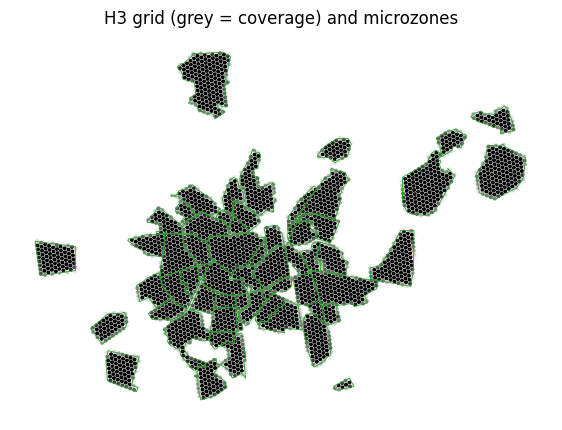

In [ ]:
OUT.mkdir(parents=True, exist_ok=True)
MZ = CONFIG["microzones"]
mz = read_layer(MZ, "microzones")
assert mz is not None, "Microzones are required"
mz["mz_area_ha"] = mz.area / 1e4
study_area = mz.union_all()

hexes = build_h3_grid(study_area, CONFIG["h3_res"], CONFIG["min_hex_coverage"])
hexes["area_ha"] = hexes["inside_area_m2"] / 1e4

# majority microzone per hex
_p = _pieces(mz, [MZ["id_col"]], hexes)
hexes["mz_id"] = hexes["h3_index"].map(_p.sort_values("piece_m2").groupby("h3_index")[MZ["id_col"]].last())

print(f"H3 res {CONFIG['h3_res']}: {len(hexes)} hexes, edge ~{h3.average_hexagon_edge_length(CONFIG['h3_res'], unit='m'):.0f} m, "
      f"study area {study_area.area/1e6:.1f} km2")
print("Population totals in microzone file (pick population_col accordingly):",
      {c: int(mz[c].sum()) for c in ["PopGrid_No", "obyv_sum", "obyv_vek_c", "sum_BOBYOS"] if c in mz})

ax = hexes.plot(column="coverage", cmap="Greys", figsize=(7, 7), edgecolor="white", linewidth=0.2)
mz.boundary.plot(ax=ax, color="tab:green", linewidth=0.6)
ax.set_title("H3 grid (grey = coverage) and microzones"); ax.set_axis_off()

### 4.1 Urban Atlas 2021 land use

Urban Atlas 2021 (1,940 polygons, 23 classes, clipped to the microzones) adds three things:

| Use | Classes (`code_2021`) | Result per hex |
|---|---|---|
| **Vacant land** as extra opportunity | 13400 land without current use, 13300 construction sites | `raw_vacant_share` (0-1) |
| **Constraints**: no GI possible | 12210 fast transit roads, 12230 railways, 12400 airport, 50000 water | `raw_constraint_share` (0-1), multiplies feasibility by (1 - share) |
| **Residential mask** for population | 11100-11300 residential fabric | residents are placed only in buildings inside residential areas |

Ignore the `area` and `perimeter` attributes of the file: they are the sizes of the original, unclipped polygons.
Soil sealing is **not** taken from Urban Atlas: it comes from the Copernicus Imperviousness raster (section 5.4).

In [ ]:
print("Urban Atlas")
UA = CONFIG["urban_atlas"]
ua = read_layer(UA, "Urban Atlas 2021")
ua_res = None
if ua is not None:
    ua = ua.assign(_code=ua[UA["code_col"]].astype(str))
    vac = ua[ua["_code"].isin(UA["vacant_codes"])]
    con = ua[ua["_code"].isin(UA["constraint_codes"])]
    hexes["raw_vacant_share"] = share_to_hex(vac, hexes) if len(vac) else 0.0
    hexes["raw_constraint_share"] = share_to_hex(con, hexes) if len(con) else 0.0
    ua_res = ua[ua["_code"].isin(UA["residential_codes"])]
    print(f"    vacant land {vac.area.sum()/1e4:.1f} ha | constraints {con.area.sum()/1e4:.1f} ha | "
          f"residential {ua_res.area.sum()/1e4:.1f} ha")
    display(hexes[["raw_vacant_share", "raw_constraint_share"]].describe().T.round(3))

Urban Atlas
  + Urban Atlas 2021: 1940 features from UrbanAtlas2021_microzone_EPSG5514.geojson
    vacant land 45.7 ha | constraints 40.7 ha | residential 1339.7 ha


,count,mean,std,min,25%,50%,75%,max
raw_vacant_share,2999.0,0.012,0.076,0.0,0.0,0.0,0.0,1.0
raw_constraint_share,2999.0,0.012,0.065,0.0,0.0,0.0,0.0,1.0


## 5. Raw indicators per hex

All raw values are stored as `raw_<indicator>` columns. They keep their original units so you can check them.

### 5.1 Urban heat (Hazard & Exposure)

* `raw_heatwave_tmax` (degC): Citiq heatwave maximum air temperature (`HW_T_C`): mean of the daily maximum
  (10:00-17:00) over the heatwave days, interpolated from 8 stations. Air temperature, complementing surface temperature.
  Do not also put the same 8 stations in `sensors`, or they count twice.
* `raw_heatwave_tmin` (degC): Citiq heatwave minimum (night) air temperature: mean of the daily minimum (20:00-08:00)
  over the heatwave days, same 8 stations. Warm nights are when the urban heat island is strongest and when
  older residents suffer most, so day and night heat get equal weight.
* `raw_lst_copernicus` (degC): Copernicus LST raster.
* `raw_lst_microzone` (degC): microzone `Termal_MEA`, area-weighted. Always available, finer than 1 km LST.
* `raw_air_temp_sensors` (degC): IDW of ENCLOD / Invipo sensors (only within `max_dist_m` of a sensor).
* `raw_heat_island`: CITIQ heat island intensity (0 outside polygons).

In [ ]:
print("Urban heat")
spec = CONFIG["heatwave_tmax"]
if spec.get("path") and Path(spec["path"]).exists():
    print(f"  + heatwave Tmax: {Path(spec['path']).name}")
    hexes["raw_heatwave_tmax"] = raster_to_hex(spec["path"], hexes, spec["band"], spec["scale"], spec["offset"], kelvin_to_c=True)
elif spec.get("path"):
    print(f"  ! heatwave Tmax: file not found ({Path(spec['path']).resolve()}), skipped")
else:
    print("  - heatwave Tmax: not configured, skipped")

spec = CONFIG["heatwave_tmin"]
if spec.get("path") and Path(spec["path"]).exists():
    print(f"  + heatwave Tmin (night): {Path(spec['path']).name}")
    hexes["raw_heatwave_tmin"] = raster_to_hex(spec["path"], hexes, spec["band"], spec["scale"], spec["offset"], kelvin_to_c=True)
elif spec.get("path"):
    print(f"  ! heatwave Tmin: file not found ({Path(spec['path']).resolve()}), skipped")
else:
    print("  - heatwave Tmin: not configured, skipped")

spec = CONFIG["lst_raster"]
if spec.get("path") and Path(spec["path"]).exists():
    print(f"  + satellite LST (Landsat): {Path(spec['path']).name}")
    hexes["raw_lst_copernicus"] = raster_to_hex(spec["path"], hexes, spec["band"], spec["scale"], spec["offset"], kelvin_to_c=True)
else:
    print("  - satellite LST: not configured, skipped (microzone thermal mean still used)")

if MZ.get("lst_col") in mz:
    hexes["raw_lst_microzone"] = intensive_to_hex(mz, [MZ["lst_col"]], hexes)[MZ["lst_col"]]
    print(f"  + microzone LST ({MZ['lst_col']})")

spec = CONFIG["sensors"]
df = read_table(spec, "sensors")
if df is not None:
    pts = table_to_points(df, spec["lat_col"], spec["lon_col"])
    hexes["raw_air_temp_sensors"] = idw_to_hex(pts, spec["value_col"], hexes, spec["idw_power"], spec["max_dist_m"])

spec = CONFIG["heat_islands"]
if spec.get("path") and Path(spec["path"]).exists():
    if spec["kind"] == "raster":
        hexes["raw_heat_island"] = raster_to_hex(spec["path"], hexes)
    else:
        hi = read_layer(spec, "heat islands")
        hexes["raw_heat_island"] = intensive_to_hex(hi, [spec["value_col"]], hexes)[spec["value_col"]].fillna(0)
else:
    print("  - heat islands: not configured, skipped")

hexes.filter(like="raw_").describe().T.round(2)

Urban heat
  + heatwave Tmax: HWmax_T_C.tif
    pixel ~50 m: averaged 69,664 pixels into hexes
  + heatwave Tmin (night): HWmin_T_C.tif
    pixel ~50 m: averaged 69,664 pixels into hexes
  + satellite LST (Landsat): LST_landsat_microzone_EPSG5514.tif
    pixel ~30 m: averaged 41,978 pixels into hexes
  + microzone LST (Termal_MEA)
  - sensors: not configured, skipped
  - heat islands: not configured, skipped


,count,mean,std,min,25%,50%,75%,max
raw_vacant_share,2999.0,0.01,0.08,0.00,0.00,0.00,0.00,1.00
raw_constraint_share,2999.0,0.01,0.06,0.00,0.00,0.00,0.00,1.00
raw_heatwave_tmax,2999.0,34.27,0.07,33.99,34.23,34.27,34.30,34.49
raw_heatwave_tmin,2999.0,20.11,0.07,19.84,20.06,20.10,20.16,20.33
raw_lst_copernicus,2998.0,29.50,3.23,15.33,27.44,29.62,31.79,38.00
raw_lst_microzone,2999.0,28.99,1.43,25.79,28.46,29.24,29.81,32.20


### 5.2 Exposure (people)

* **Residents:** microzone population is split into hexes in proportion to **building footprint area** when a buildings
  layer is given (dasymetric), otherwise by area. With Urban Atlas, only buildings inside **residential** land use are
  used, so people are not placed in factories or shopping centres. Public buildings (schools, offices,
  hospitals) are left out too, since nobody lives there. A microzone with no residential buildings falls back
  to all its area. Totals are preserved, which is checked in section 8.
* **Daytime presence:** Vodafone SIM counts averaged over `day_hours`, split the same way from their zones, and
  scaled to people so that the night-time total equals residents (`calibrate_to_residents`). If you enter
  `city_daytime_population` from Kam dojizdime, daytime is rescaled to that total instead.
  **Without Vodafone**, a proxy is used: residents + UP staff + UP students. Note that students and staff are already
  inside Vodafone counts, so UP data is never added on top of Vodafone (no double counting).
* Both are converted to **people per hectare** of the hex part inside the study area.

In [ ]:
print("Exposure")
bld = read_layer(CONFIG["buildings"], "buildings (dasymetric weights)")
pop_col = MZ["population_col"]

# public / private category (column set in the config, or found automatically)
bld_public = None
if bld is not None:
    bs = CONFIG["buildings"]
    pats = [p.lower() for p in bs.get("public_patterns", [])]
    is_pub = lambda s: s.astype(str).str.lower().str.contains("|".join(pats), regex=True, na=False)
    own = bs.get("ownership_col")
    if own is None:
        for c in bld.columns:
            if c != "geometry" and bld[c].dtype.kind in "OU" or str(bld[c].dtype) in ("string", "str"):
                if c != "geometry" and is_pub(bld[c]).any():
                    own = c
                    break
    if own is not None and own in bld:
        bld_public = is_pub(bld[own])
        print(f"    ownership column '{own}': {int(bld_public.sum()):,} public of {len(bld):,} buildings")
        print(f"    values: {bld[own].value_counts(dropna=False).head(8).to_dict()}")
    else:
        print("    ! no public/private column found: set buildings.ownership_col in the config")

bld_res = bld if bld_public is None else bld[~bld_public]
if bld is not None and ua_res is not None and len(ua_res):
    # residents live in residential areas: keep only buildings whose centre lies in Urban Atlas residential fabric
    pts = gpd.GeoDataFrame(geometry=bld_res.representative_point(), crs=bld.crs)
    inside = gpd.sjoin(pts, ua_res[["geometry"]], predicate="within").index.unique()
    bld_res = bld_res.loc[inside]
    print(f"    residential buildings: {len(bld_res):,} of {len(bld):,} (Urban Atlas residential classes"
          f"{', public buildings excluded' if bld_public is not None else ''})")
hexes["raw_residents"] = extensive_to_hex(mz, MZ["id_col"], [pop_col], hexes, weights=bld_res)[pop_col]

vs = CONFIG["vodafone"]
day_people = None
vz = read_layer({"path": vs.get("zones_path"), "layer": vs.get("zones_layer")}, "Vodafone zones")
if vz is not None and vs.get("table_path"):
    tp = Path(vs["table_path"])
    vt = (gpd.read_file(tp, layer=vs.get("table_layer")) if tp.suffix.lower() in (".gdb", ".gpkg", ".geojson", ".shp")
          else read_table({"path": tp}, "Vodafone table"))
    vt = pd.DataFrame(vt.drop(columns="geometry", errors="ignore"))
    for k, v in (vs.get("filter") or {}).items():
        vt = vt[vt[k] == v]
    day = vt[vt[vs["hour_col"]].isin(vs["day_hours"])].groupby(vs["table_zone_col"])[vs["count_col"]].mean()
    night = vt[vt[vs["hour_col"]].isin(vs["night_hours"])].groupby(vs["table_zone_col"])[vs["count_col"]].mean()
    vz = vz.assign(sim_day=vz[vs["zone_id_col"]].map(day).fillna(0), sim_night=vz[vs["zone_id_col"]].map(night).fillna(0))
    vz = vz[vz.intersects(study_area)]
    tr = extensive_to_hex(vz, vs["zone_id_col"], ["sim_day", "sim_night"], hexes, weights=bld)
    k = hexes["raw_residents"].sum() / tr["sim_night"].sum() if vs["calibrate_to_residents"] and tr["sim_night"].sum() > 0 else 1.0
    day_people = tr["sim_day"] * k
    print(f"    Vodafone daytime presence, SIM-to-people factor k = {k:.2f}")
else:
    ups = CONFIG["up_workplaces"]
    w = read_table(ups, "UP workplaces (daytime proxy)")
    extra = pd.Series(0.0, index=hexes.index)
    if w is not None:
        w = w.copy()
        st = read_table(CONFIG["up_students"], "UP students")
        w["_people"] = w[ups["staff_col"]].fillna(0) if ups.get("staff_col") else 0.0
        if st is not None:
            s_by_dept = st.groupby(CONFIG["up_students"]["dept_col"])[CONFIG["up_students"]["count_col"]].sum()
            n_sites = w.groupby(ups["dept_col"])[ups["dept_col"]].transform("count")
            w["_people"] += w[ups["dept_col"]].map(s_by_dept).fillna(0) / n_sites   # spread a department over its sites
        extra = points_to_hex(table_to_points(w, ups["lat_col"], ups["lon_col"]), hexes, "_people")
    day_people = hexes["raw_residents"] + extra
    print(f"    daytime proxy = residents + UP people ({extra.sum():,.0f} added)")

if CONFIG.get("city_daytime_population"):
    day_people = day_people * CONFIG["city_daytime_population"] / day_people.sum()
    print(f"    rescaled daytime total to {CONFIG['city_daytime_population']:,}")

hexes["raw_day_people"] = day_people
hexes["raw_res_density"] = hexes["raw_residents"] / hexes["area_ha"]
hexes["raw_day_density"] = hexes["raw_day_people"] / hexes["area_ha"]
hexes[["raw_residents", "raw_day_people", "raw_res_density", "raw_day_density"]].describe().T.round(1)

Exposure
  + buildings (dasymetric weights): 22232 features from buildings_with_class.geojson
    ownership column 'building_category': 813 public of 22,232 buildings
    values: {'private': 21419, 'public': 813}
    residential buildings: 15,805 of 22,232 (Urban Atlas residential classes, public buildings excluded)
  - Vodafone zones: not configured, skipped
  - UP workplaces (daytime proxy): not configured, skipped
    daytime proxy = residents + UP people (0 added)


,count,mean,std,min,25%,50%,75%,max
raw_residents,2999.0,33.8,61.5,0.0,0.0,1.9,40.6,451.5
raw_day_people,2999.0,33.8,61.5,0.0,0.0,1.9,40.6,451.5
raw_res_density,2999.0,25.4,45.9,0.0,0.0,1.6,31.2,533.6
raw_day_density,2999.0,25.4,45.9,0.0,0.0,1.6,31.2,533.6


### 5.3 Vulnerability (sensitive groups)

Heat hits some people much harder: older residents (especially 75+), young children, and people using schools,
kindergartens and doctors' surgeries.

* `raw_share_65plus`, `raw_share_75plus`, `raw_share_0_4` (0-1): share of residents in each age group, from the
  microzone `obyv_vek_*` columns (0-4, 5-14, 15-24, 25-39, 40-64, 65-74, 75+). A share is a rate, so each hex gets
  the area-weighted value of its microzone(s). Microzones with fewer than `min_residents_for_shares` residents get a
  blank share, because "100% over 65" in a zone with 2 people is noise.
* `raw_sensitive_facilities` (count per hex): kindergartens + primary schools + doctors, spread from microzones by area
  (or by building area when a buildings layer is configured).

Hexes with no residents and no facilities get vulnerability 0 (nobody vulnerable to protect).

### 5.4 Green supply and access to green (Green Deficit)

* `raw_green_share` (0-1): share of the hex covered by green polygons (Urban Atlas / OSM) when configured; otherwise
  the microzone green land cover (forest + small woody + grassland, ha) divided by microzone area.
* `raw_tree_cover` (%): Copernicus Tree Cover Density raster, otherwise microzone `TreeCoverD`.
* `raw_vegetation_share` (0-1): share of the hex with dense green vegetation in summer 2026 (Sentinel-2 NDVI >=
  `veg_threshold`). Sees courtyard trees, street trees and lawns that the Copernicus tree layer misses.
  `raw_ndvi_mean` keeps the mean NDVI for the portal.
* `raw_sealing` (0-1): share of sealed ground from the Copernicus Imperviousness Density raster (0-100 %). Skipped
  until the raster is configured; the other green supply indicators then share the weight.
* `raw_green_per_capita` (m2/person): microzone green area / microzone residents. Microzones without residents get NaN
  (no residents lacking green), which later counts as no deficit.
* `raw_dist_green` (m): distance from the hex centre to the nearest green area of at least `green_min_area_ha`:
  * **network distance** on the roads layer (walkable classes) when roads and green polygons are configured,
  * with green polygons but no roads: **straight-line distance** to the nearest such green area,
  * with neither: **H3 grid distance** to the nearest hex with `raw_green_share >= 0.25` (rough).

In [ ]:
print("Vulnerability")
tot = mz[MZ["age_total_col"]]
ok = tot >= MZ["min_residents_for_shares"]
mzv = mz.assign(
    _s65=np.where(ok, mz[MZ["age_65plus_cols"]].sum(axis=1) / tot.where(ok), np.nan),
    _s75=np.where(ok, mz[MZ["age_75plus_cols"]].sum(axis=1) / tot.where(ok), np.nan),
    _s04=np.where(ok, mz[MZ["age_0_4_cols"]].sum(axis=1) / tot.where(ok), np.nan),
    _fac=mz[MZ["facility_cols"]].sum(axis=1),
)
print(f"    age shares from {MZ['age_total_col']}; {int((~ok).sum())} microzones below "
      f"{MZ['min_residents_for_shares']} residents left blank")
sh = intensive_to_hex(mzv, ["_s65", "_s75", "_s04"], hexes)
hexes["raw_share_65plus"], hexes["raw_share_75plus"], hexes["raw_share_0_4"] = sh["_s65"], sh["_s75"], sh["_s04"]
hexes["raw_sensitive_facilities"] = extensive_to_hex(mzv, MZ["id_col"], ["_fac"], hexes, weights=bld)["_fac"]
print(f"    sensitive facilities: {int(mz[MZ['facility_cols']].sum().sum())} ({', '.join(MZ['facility_cols'])})")
hexes[["raw_share_65plus", "raw_share_75plus", "raw_share_0_4", "raw_sensitive_facilities"]].describe().T.round(3)

Vulnerability
    age shares from obyv_vek_c; 8 microzones below 50 residents left blank
    sensitive facilities: 165 (PocetMS, PocetZS, PocetLekar)


,count,mean,std,min,25%,50%,75%,max
raw_share_65plus,2712.0,0.218,0.048,0.121,0.183,0.220,0.244,0.333
raw_share_75plus,2712.0,0.096,0.036,0.036,0.073,0.088,0.103,0.198
raw_share_0_4,2712.0,0.046,0.017,0.003,0.037,0.042,0.050,0.133
raw_sensitive_facilities,2999.0,0.055,0.090,0.000,0.000,0.010,0.073,0.857


In [ ]:
print("Green supply")
green = []
for i, spec in enumerate(CONFIG["green_polygons"]):
    g = read_layer(spec, f"green layer {i+1}")
    if g is None:
        continue
    if spec.get("column"):
        g = g[g[spec["column"]].astype(str).isin([str(v) for v in spec["values"]])]
    green.append(g[["geometry"]])
green = pd.concat(green, ignore_index=True) if green else None

if green is not None and len(green):
    hexes["raw_green_share"] = share_to_hex(green, hexes)
    print("    green share from polygons")
else:
    mzg = mz.assign(_gshare=(mz[MZ["green_ha_cols"]].sum(axis=1) / mz["mz_area_ha"]).clip(0, 1))
    hexes["raw_green_share"] = intensive_to_hex(mzg, ["_gshare"], hexes)["_gshare"]
    print(f"    green share from microzone columns {MZ['green_ha_cols']}")

spec = CONFIG["tree_cover_raster"]
if spec.get("path") and Path(spec["path"]).exists():
    print(f"  + tree cover raster: {Path(spec['path']).name}")
    tc = raster_to_hex(spec["path"], hexes, spec["band"])
    hexes["raw_tree_cover"] = tc.where(tc <= 100)       # drop HRL codes 254/255
else:
    if spec.get("path"):
        print(f"  ! tree cover raster: file not found ({Path(spec['path']).resolve()}), using microzone values")
    hexes["raw_tree_cover"] = intensive_to_hex(mz, [MZ["tree_cover_col"]], hexes)[MZ["tree_cover_col"]]
    print(f"    tree cover from microzone {MZ['tree_cover_col']}")

spec = CONFIG["imperviousness_raster"]
if spec.get("path") and Path(spec["path"]).exists():
    print(f"  + imperviousness raster: {Path(spec['path']).name}")
    imp = raster_to_hex(spec["path"], hexes, spec["band"])
    hexes["raw_sealing"] = imp.where(imp <= 100) / 100      # 0-1 share sealed; drops HRL codes 254/255
elif spec.get("path"):
    print(f"  ! imperviousness raster: file not found ({Path(spec['path']).resolve()}), sealing skipped")
else:
    print("  - imperviousness raster: not configured, sealing skipped")

spec = CONFIG.get("ndvi_raster", {})
if spec.get("path") and Path(spec["path"]).exists():
    print(f"  + NDVI raster: {Path(spec['path']).name}")
    nd_mean = raster_to_hex(spec["path"], hexes, spec["band"], spec["scale"], spec["offset"])
    if nd_mean.max() > 1.5 or nd_mean.min() < -1.5:
        print(f"    ! NDVI values {nd_mean.min():.1f} to {nd_mean.max():.1f} are outside -1..1: set scale/offset in the config")
    hexes["raw_ndvi_mean"] = nd_mean.where(nd_mean.abs() <= 1)
    hexes["raw_vegetation_share"] = raster_to_hex(spec["path"], hexes, spec["band"], spec["scale"], spec["offset"],
                                                  threshold=spec.get("veg_threshold", 0.5))
    print(f"    vegetation share (NDVI >= {spec.get('veg_threshold', 0.5)}): mean {hexes['raw_vegetation_share'].mean():.0%}")
elif spec.get("path"):
    print(f"  ! NDVI raster: file not found ({Path(spec['path']).resolve()}), skipped")
else:
    print("  - NDVI raster: not configured, skipped")

mzc = mz.assign(_gpc=np.where(mz[pop_col] > 0, mz[MZ["green_ha_cols"]].sum(axis=1) * 1e4 / mz[pop_col].replace(0, np.nan), np.nan))
hexes["raw_green_per_capita"] = intensive_to_hex(mzc, ["_gpc"], hexes)["_gpc"]

Green supply
  + green layer 1: 1940 features from UrbanAtlas2021_microzone_EPSG5514.geojson
    green share from polygons
  + tree cover raster: copernicusTreeCoverDensity10m.tif
    pixel ~10 m: averaged 378,018 pixels into hexes
  + imperviousness raster: olumouc2024_imperviousness_nodata.tif
    pixel ~10 m: averaged 378,101 pixels into hexes
  + NDVI raster: NDVI_microzone_EPSG5514.tif
    pixel ~10 m: averaged 378,144 pixels into hexes
    pixel ~10 m: averaged 378,144 pixels into hexes
    vegetation share (NDVI >= 0.5): mean 37%


In [ ]:
print("Access to green")
rs = CONFIG["roads"]
roads = read_layer(rs, "roads")

def network_distance_to_green(roads, green_big, hexes, snap=30, max_dist=3000):
    import networkx as nx
    from scipy.spatial import cKDTree
    if rs.get("class_col"):
        cls = roads[rs["class_col"]]
        roads = roads[cls.notna() & (cls.astype(str) != "") & ~cls.isin(rs["walk_exclude"])]   # drop non-roads (rail, rivers)
    import shapely
    # node the network (split lines where they cross) and add vertices every 25 m so green areas can be snapped
    noded = shapely.segmentize(shapely.union_all(roads.geometry.to_numpy()), 25)
    lines = gpd.GeoSeries([noded], crs=roads.crs).explode(index_parts=False)
    lines = lines[lines.geom_type == "LineString"]
    G = nx.Graph()
    for geom in lines:
        cs = [(round(x, 1), round(y, 1)) for x, y in geom.coords]
        for a, b in zip(cs[:-1], cs[1:]):
            if a != b:
                G.add_edge(a, b, w=math.dist(a, b))
    nodes = np.array(G.nodes)
    tree = cKDTree(nodes)
    # sources: nodes within `snap` m of a green area boundary or inside it
    samples = []
    for poly in green_big.geometry:
        b = poly.boundary
        n = max(int(b.length // 20), 4)
        samples += [b.interpolate(i / n, normalized=True).coords[0] for i in range(n)]
    hits = set()
    for lst in tree.query_ball_point(np.array(samples), r=snap):
        hits.update(lst)
    inside = gpd.sjoin(gpd.GeoDataFrame(geometry=gpd.points_from_xy(nodes[:, 0], nodes[:, 1]), crs=green_big.crs),
                       green_big[["geometry"]], predicate="within").index
    hits.update(inside)
    src = [tuple(nodes[i]) for i in hits]
    if not src:
        print("    ! no road nodes near green areas, using straight-line distance instead")
        return None
    dist = nx.multi_source_dijkstra_path_length(G, src, cutoff=max_dist, weight="w")
    nd = np.array([dist.get(tuple(n), np.inf) for n in nodes])
    c = hexes.geometry.centroid
    # try the 10 nearest street nodes (within 300 m) and keep the best route: a hex next to a short, isolated
    # street fragment would otherwise get no route at all
    d0, idx = tree.query(np.c_[c.x, c.y], k=min(10, len(nodes)), distance_upper_bound=300)
    valid = np.isfinite(d0)
    total = np.where(valid, d0 + nd[np.minimum(idx, len(nodes) - 1)], np.inf)
    net = total.min(axis=1)
    # straight-line distance with a walking detour factor, used where the street network cannot reach a park
    # (streets-only data has no footpaths into parks) or gives an implausibly long detour
    sl = gpd.sjoin_nearest(gpd.GeoDataFrame(geometry=c, crs=hexes.crs), green_big[["geometry"]],
                           distance_col="_d")["_d"].groupby(level=0).min().reindex(hexes.index).to_numpy()
    fallback = sl * rs.get("detour_factor", 1.3)
    use_fb = ~np.isfinite(net) | (net > 2 * fallback + 100)
    out = np.minimum(np.where(use_fb, fallback, net), max_dist)
    in_green = gpd.sjoin(gpd.GeoDataFrame(geometry=c, crs=hexes.crs), green_big[["geometry"]], predicate="within").index
    out[np.isin(np.arange(len(out)), in_green)] = 0
    print(f"    network: {G.number_of_nodes():,} nodes, {len(src):,} green access nodes; "
          f"{int(use_fb.sum())} hexes use straight-line x {rs.get('detour_factor', 1.3)} (no usable street route)")
    return pd.Series(out, index=hexes.index)

if roads is not None and green is not None and len(green):
    gb = gpd.GeoDataFrame(geometry=[green.union_all()], crs=green.crs).explode(index_parts=False)
    gb = gb[gb.area >= CONFIG["green_min_area_ha"] * 1e4]
    print(f"    {len(gb)} green areas >= {CONFIG['green_min_area_ha']} ha")
    nd = network_distance_to_green(roads, gb, hexes, rs["snap_m"], rs["max_dist_m"])
    if nd is not None:
        hexes["raw_dist_green"] = nd
if "raw_dist_green" not in hexes and green is not None and len(green):
    # no roads: straight-line distance from hex centre to the nearest green area >= green_min_area_ha
    gb = gpd.GeoDataFrame(geometry=[green.union_all()], crs=green.crs).explode(index_parts=False)
    gb = gb[gb.area >= CONFIG["green_min_area_ha"] * 1e4]
    c = gpd.GeoDataFrame(geometry=hexes.geometry.centroid, crs=hexes.crs)
    hexes["raw_dist_green"] = gpd.sjoin_nearest(c, gb, distance_col="_d")["_d"].groupby(level=0).min().reindex(hexes.index)
    print(f"    straight-line distance to {len(gb)} green areas >= {CONFIG['green_min_area_ha']} ha (no roads layer)")
if "raw_dist_green" not in hexes:
    mask = hexes["raw_green_share"] >= 0.25
    hexes["raw_dist_green"] = grid_distance_to(mask, hexes)
    print(f"    fallback: H3 grid distance to {int(mask.sum())} hexes with green share >= 25%")

hexes[["raw_green_share", "raw_tree_cover", "raw_green_per_capita", "raw_dist_green"]].describe().T.round(2)

Access to green
  + roads: 3355 features from roads.geojson
    109 green areas >= 0.5 ha
    network: 25,083 nodes, 2,987 green access nodes; 1262 hexes use straight-line x 1.3 (no usable street route)


,count,mean,std,min,25%,50%,75%,max
raw_green_share,2999.0,0.07,0.19,0.0,0.00,0.00,0.00,1.00
raw_tree_cover,2999.0,5.37,13.54,0.0,0.00,0.00,3.66,91.38
raw_green_per_capita,2986.0,655.01,1145.24,0.0,90.50,312.15,848.12,8356.06
raw_dist_green,2999.0,399.32,410.86,0.0,102.66,275.60,544.49,2493.39


### 5.5 Opportunity land, linear corridors and buildings (Feasibility)

* `raw_brownfield_share` (0-1): share of hex covered by brownfields.
* `raw_parking` (spaces / ha): free spaces from the occupancy table (capacity x (1 - occupancy)), otherwise
  microzone parking spaces spread by area. Large, little-used car parks are depaving candidates.
* `raw_municipal_share` (0-1): share of hex on city-owned land.
* `raw_public_building_share` (0-1): share of the hex covered by **public** building footprints (schools, offices,
  hospitals, sports halls). Public owners can act faster: green roofs, schoolyard greening, depaving courtyards.
  `raw_public_roof_m2` keeps the footprint area for the portal.
* `raw_cycle_density` (m / ha): cycle path length per hex, fallback microzone `Cyklostezk` (km) spread by area.
* `raw_street_density` (m / ha): street length (street classes) from the roads layer, fallback microzone sidewalks.
* `raw_up_energy` (value_col units): UP building energy use, joined to workplaces by building name (optional component).

In [ ]:
print("Opportunity land")
bf = read_layer(CONFIG["brownfields"], "brownfields")
if bf is not None:
    hexes["raw_brownfield_share"] = share_to_hex(bf, hexes)

ml = read_layer(CONFIG["municipal_land"], "municipal land")
if ml is not None:
    hexes["raw_municipal_share"] = share_to_hex(ml, hexes)

if globals().get("bld_public") is not None and bld_public.any():
    pub = bld[bld_public]
    pp = _pieces(pub.assign(_k=1), ["_k"], hexes)
    roof = pp.groupby("h3_index")["piece_m2"].sum()
    hexes["raw_public_roof_m2"] = hexes["h3_index"].map(roof).fillna(0)
    hexes["raw_public_building_share"] = (hexes["raw_public_roof_m2"] / hexes["inside_area_m2"]).clip(0, 1)
    print(f"    public buildings: {len(pub):,} ({pub.area.sum()/1e4:.1f} ha of footprint) in "
          f"{int((hexes['raw_public_roof_m2'] > 0).sum())} hexes")

ps = CONFIG["parking"]
pk = read_table(ps, "parking occupancy")
if pk is not None:
    occ = pk[ps["occupancy_col"]] if ps["occupancy_is_share"] else pk[ps["occupancy_col"]] / pk[ps["capacity_col"]]
    pk = pk.assign(_free=pk[ps["capacity_col"]] * (1 - occ.clip(0, 1)))
    hexes["raw_parking"] = points_to_hex(table_to_points(pk, ps["lat_col"], ps["lon_col"]), hexes, "_free") / hexes["area_ha"]
    print("    free parking spaces from occupancy table")
elif MZ.get("parking_spaces_col") in mz:
    col = MZ["parking_spaces_col"]
    hexes["raw_parking"] = extensive_to_hex(mz, MZ["id_col"], [col], hexes)[col] / hexes["area_ha"]
    print(f"    parking spaces from microzone {col} (spread by area)")

print("Linear corridors")
cp = read_layer(CONFIG["cycle_paths"], "cycle paths")
if cp is not None:
    hexes["raw_cycle_density"] = length_to_hex(cp, hexes) / hexes["area_ha"]
elif MZ.get("cycle_km_col") in mz:
    col = MZ["cycle_km_col"]
    hexes["raw_cycle_density"] = extensive_to_hex(mz, MZ["id_col"], [col], hexes)[col] * 1000 / hexes["area_ha"]
    print(f"    cycle paths from microzone {col} (spread by area)")

if roads is not None:
    st = roads[roads[rs["class_col"]].isin(rs["street_classes"])] if rs.get("class_col") else roads
    hexes["raw_street_density"] = length_to_hex(st, hexes) / hexes["area_ha"]
    print("    street length from roads layer")
elif MZ.get("sidewalk_km_col") in mz:
    col = MZ["sidewalk_km_col"]
    hexes["raw_street_density"] = extensive_to_hex(mz, MZ["id_col"], [col], hexes)[col] * 1000 / hexes["area_ha"]
    print(f"    sidewalks from microzone {col} (spread by area)")

print("Buildings (optional)")
es, ws = CONFIG["up_energy"], CONFIG["up_workplaces"]
en = read_table(es, "UP energy")
wk = read_table(ws, "UP workplaces") if en is not None else None
if en is not None and wk is not None:
    if es.get("year_col") and es.get("year") is not None:
        en = en[en[es["year_col"]] == es["year"]]
    e = en.groupby(es["building_col"])[es["value_col"]].mean()
    wk = wk.assign(_energy=wk[ws["name_col"]].map(e))
    print(f"    matched {wk['_energy'].notna().sum()} of {len(e)} buildings to workplace coordinates")
    wk = wk.dropna(subset=["_energy"])
    hexes["raw_up_energy"] = points_to_hex(table_to_points(wk, ws["lat_col"], ws["lon_col"]), hexes, "_energy")

hexes.filter(regex="raw_(brown|parking|municipal|public|cycle|street|up_)").describe().T.round(2)

Opportunity land
  + brownfields: 13 features from brownfields_mz.geojson
  - municipal land: not configured, skipped
    public buildings: 813 (57.7 ha of footprint) in 661 hexes
  - parking occupancy: not configured, skipped
    parking spaces from microzone PocetParkM (spread by area)
Linear corridors
  + cycle paths: 759 features from cycle_path.geojson
    street length from roads layer
Buildings (optional)
  - UP energy: not configured, skipped


,count,mean,std,min,25%,50%,75%,max
raw_brownfield_share,2999.0,0.00,0.00,0.0,0.00,0.00,0.00,0.00
raw_public_roof_m2,2999.0,192.29,626.21,0.0,0.00,0.00,0.00,8452.34
raw_public_building_share,2999.0,0.01,0.05,0.0,0.00,0.00,0.00,0.58
raw_parking,2999.0,11.15,13.36,0.0,1.23,4.91,19.78,60.52
raw_cycle_density,2999.0,10.98,44.02,0.0,0.00,0.00,0.00,811.10
raw_street_density,2999.0,71.68,83.68,0.0,0.00,48.72,125.14,612.39


## 6. Fuzzy normalisation

This table is the **single place where the normalisation is defined**. For each indicator: membership function,
thresholds, optional log transform, component and weight inside the component. Indicators that weren't computed are
skipped and the remaining weights in that component are renormalised.

Starting thresholds and why:

* **Heat:** relative to the city (`p50` to `p95`), because absolute temperatures depend on the period and scene date.
  1 = hottest 5%. Heatwave Tmax (day) and Tmin (night) get the largest heat weights (0.3 each).
* **Densities:** log scale, 5th to 95th percentile, so the centre does not flatten everything else.
* **Age shares:** relative to the city (`p5` to `p95`): 1 = the 5% of hexes with the highest share of older
  residents or young children. 75+ is also counted on its own because heat risk rises steeply with age.
* **Sensitive facilities:** 0 at none, 1 at the 95th percentile of hexes that have any (log scale).
* **Green share:** 1 (deficit) at 10% green or less, 0 at 50% or more.
* **Tree cover:** 1 at 5% or less, 0 at 30% or more.
* **Green per capita:** 1 at 9 m2/person or less, 0 at 50 m2/person or more (commonly used urban green benchmarks).
* **Distance to green:** 0 within 300 m (WHO Europe 0.5 ha within 300 m), 1 beyond 800 m.
* **Sealing:** 0 at 30% sealed or less, 1 at 80% or more (Copernicus Imperviousness).
* **Vacant land:** like brownfields, 1 when a quarter of the hex is vacant land or a construction site.
* **Opportunity and corridors:** 0 at none, 1 at the 95th percentile of non-zero values (`p95nz`).

Calibrate them with local experts. The `thresholds_used` printout shows what each percentile resolved to.

In [ ]:
INDICATORS = {
    # name:                 (component,        function,             params,                                  log,   weight)
    # heat weights after validation: Landsat surface 45%, night-time air 30%, microzone surface 15%, daytime air 10%
    "heatwave_tmax":        ("heat",           "linear_increasing", {"low": "p50", "high": "p95"},             False, 0.10),
    "heatwave_tmin":        ("heat",           "linear_increasing", {"low": "p50", "high": "p95"},             False, 0.30),
    "lst_copernicus":       ("heat",           "linear_increasing", {"low": "p50", "high": "p95"},             False, 0.45),   # Landsat LST (30 m)
    "lst_microzone":        ("heat",           "linear_increasing", {"low": "p50", "high": "p95"},             False, 0.15),
    "air_temp_sensors":     ("heat",           "linear_increasing", {"low": "p50", "high": "p95"},             False, 0.05),
    "heat_island":          ("heat",           "linear_increasing", {"low": 0, "high": "p95nz"},               False, 0.05),
    "res_density":          ("exposure_night", "linear_increasing", {"low": "p5", "high": "p95"},              True,  1.0),
    "day_density":          ("exposure_day",   "linear_increasing", {"low": "p5", "high": "p95"},              True,  1.0),
    "share_65plus":         ("vulnerability",  "linear_increasing", {"low": "p5", "high": "p95"},              False, 0.35),
    "share_75plus":         ("vulnerability",  "linear_increasing", {"low": "p5", "high": "p95"},              False, 0.20),
    "share_0_4":            ("vulnerability",  "linear_increasing", {"low": "p5", "high": "p95"},              False, 0.20),
    "sensitive_facilities": ("vulnerability",  "linear_increasing", {"low": 0, "high": "p95nz"},               True,  0.25),
    "green_share":          ("green_supply",   "linear_decreasing", {"low": 0.10, "high": 0.50},               False, 0.20),
    "tree_cover":           ("green_supply",   "linear_decreasing", {"low": 5, "high": 30},                    False, 0.15),
    "vegetation_share":     ("green_supply",   "linear_decreasing", {"low": 0.10, "high": 0.40},               False, 0.30),
    "green_per_capita":     ("green_supply",   "linear_decreasing", {"low": 9, "high": 50},                    False, 0.15),
    "sealing":              ("green_supply",   "linear_increasing", {"low": 0.30, "high": 0.80},               False, 0.20),
    "dist_green":           ("green_access",   "linear_increasing", {"low": 300, "high": 800},                 False, 1.0),
    "brownfield_share":     ("opportunity",    "linear_increasing", {"low": 0, "high": 0.25},                  False, 0.4),
    "vacant_share":         ("opportunity",    "linear_increasing", {"low": 0, "high": 0.25},                  False, 0.3),
    "parking":              ("opportunity",    "linear_increasing", {"low": 0, "high": "p95nz"},               True,  0.3),
    "municipal_share":      ("opportunity",    "linear_increasing", {"low": 0, "high": 0.5},                   False, 0.3),
    "public_building_share":("opportunity",    "linear_increasing", {"low": 0, "high": "p95nz"},               False, 0.3),
    "cycle_density":        ("corridors",      "linear_increasing", {"low": 0, "high": "p95nz"},               False, 0.5),
    "street_density":       ("corridors",      "linear_increasing", {"low": 0, "high": "p95nz"},               False, 0.5),
    "up_energy":            ("buildings",      "linear_increasing", {"low": 0, "high": "p95nz"},               True,  1.0),
}

# how a missing (NaN) value is read after normalisation
NAN_AS = {"green_per_capita": 0.0}   # no residents -> no per-capita deficit

thresholds_used, rows = {}, []
for name, (comp, fn, params, log, w) in INDICATORS.items():
    col = f"raw_{name}"
    if col not in hexes:
        rows.append((name, comp, "not available"))
        continue
    mu, shown = fuzzy(hexes[col], fn, log=log, **params)
    if name in NAN_AS:
        mu = mu.fillna(NAN_AS[name])
    hexes[f"mu_{name}"] = mu
    thresholds_used[name] = {"component": comp, "function": fn, "log": log, "weight": w,
                             "params_spec": params, "params_resolved": shown}
    rows.append((name, comp, f"{fn} {', '.join(f'{k}={v:.3g}' for k, v in shown.items())}{' (log)' if log else ''}"))

pd.DataFrame(rows, columns=["indicator", "component", "membership (resolved thresholds, original units)"])

,indicator,component,"membership (resolved thresholds, original units)"
0,heatwave_tmax,heat,"linear_increasing low=34.3, high=34.4"
1,heatwave_tmin,heat,"linear_increasing low=20.1, high=20.3"
2,lst_copernicus,heat,"linear_increasing low=29.6, high=34.5"
3,lst_microzone,heat,"linear_increasing low=29.2, high=31.2"
4,air_temp_sensors,heat,not available
5,heat_island,heat,not available
6,res_density,exposure_night,"linear_increasing low=0, high=129 (log)"
7,day_density,exposure_day,"linear_increasing low=0, high=129 (log)"
8,share_65plus,vulnerability,"linear_increasing low=0.145, high=0.293"
9,share_75plus,vulnerability,"linear_increasing low=0.051, high=0.17"


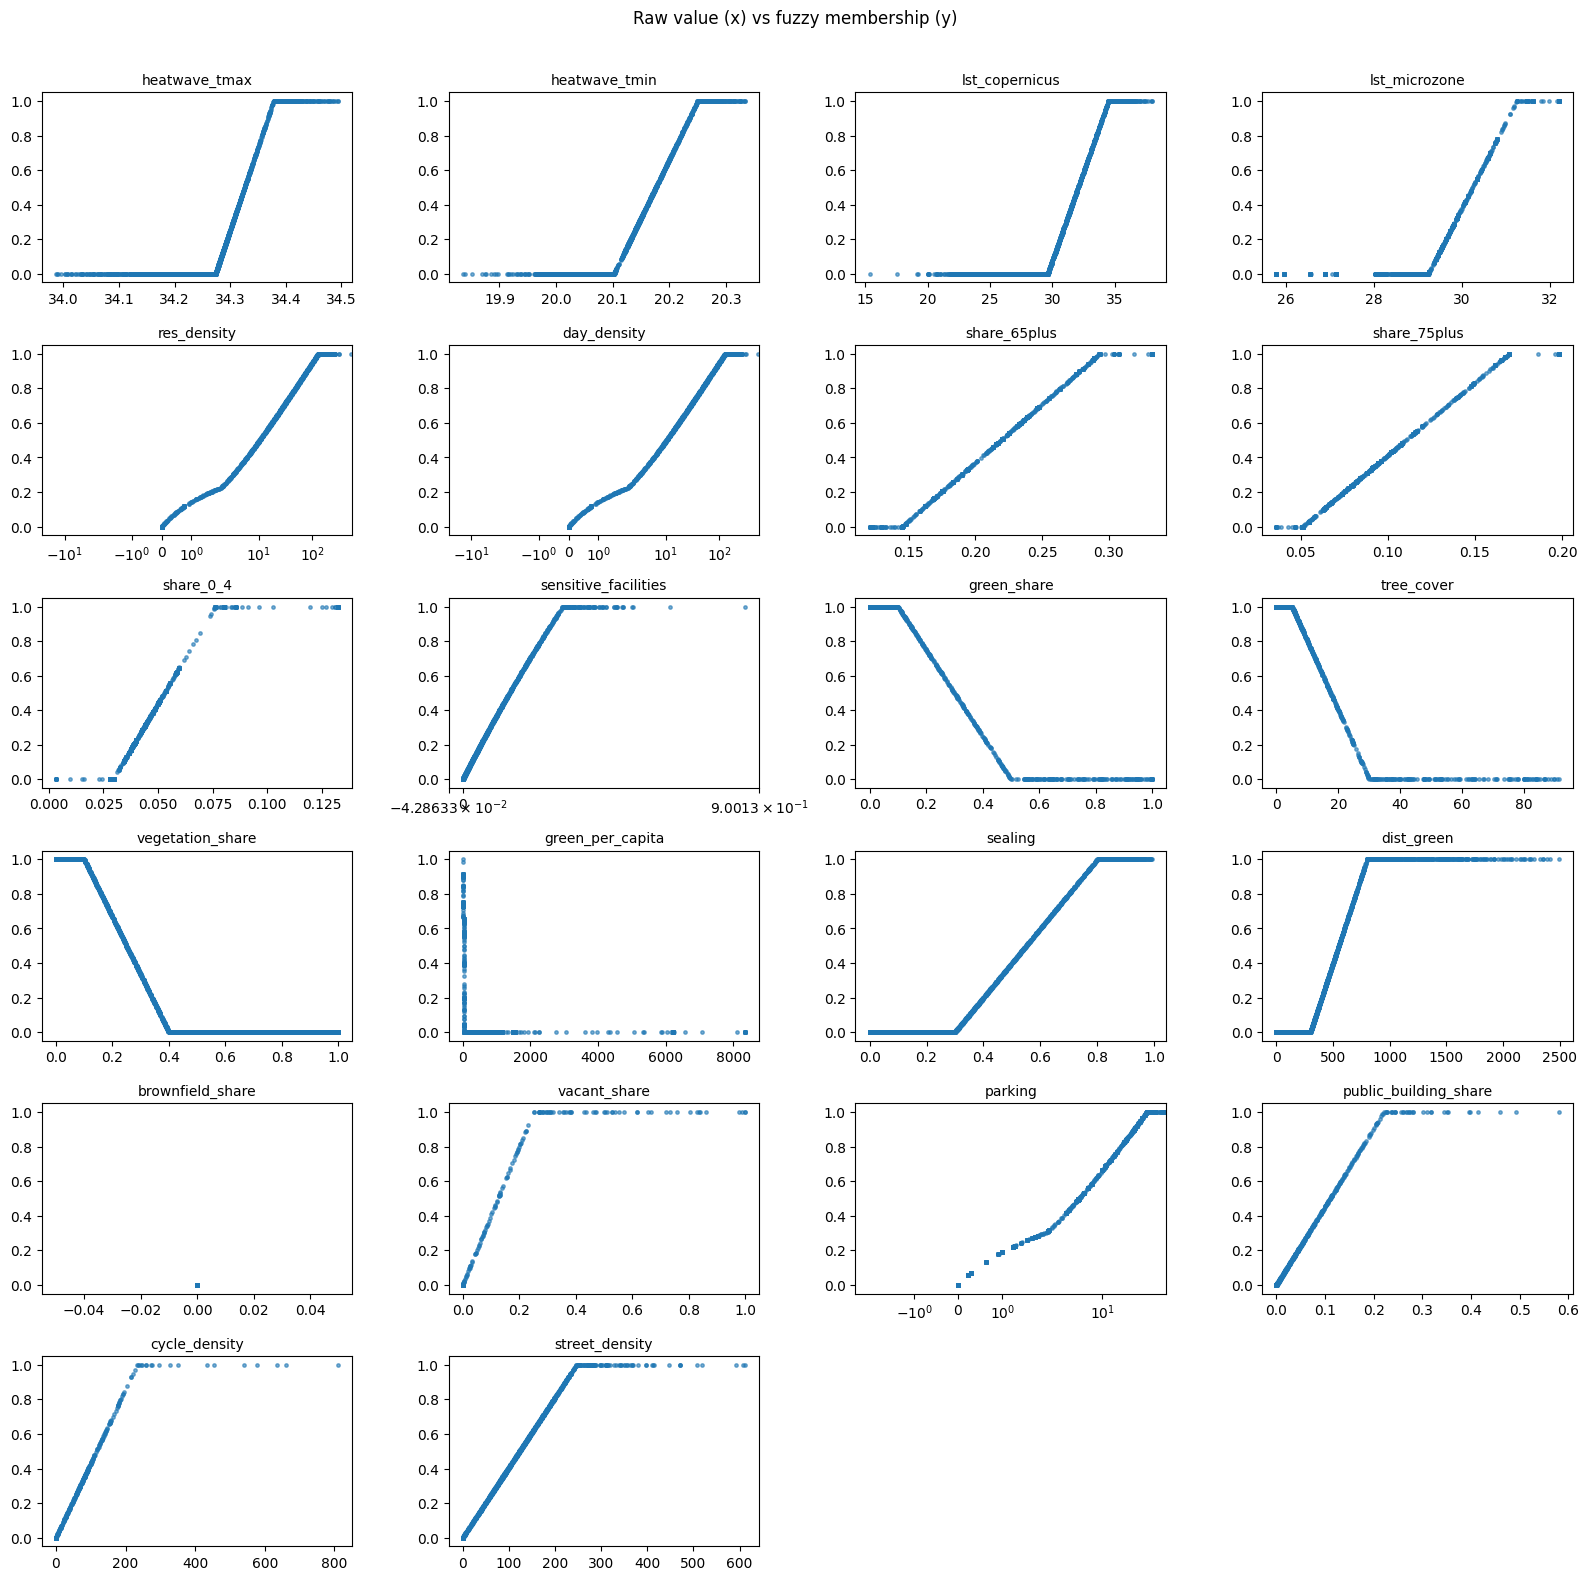

In [ ]:
mu_cols = [c for c in hexes if c.startswith("mu_")]
n = len(mu_cols); ncol = 4; nrow = math.ceil(n / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 2.6 * nrow))
for ax, c in zip(axes.flat, mu_cols):
    name = c[3:]
    raw = hexes[f"raw_{name}"]
    ax.scatter(raw, hexes[c], s=6, alpha=0.6)
    ax.set_title(name, fontsize=10); ax.set_ylim(-0.05, 1.05)
    if INDICATORS[name][3]:
        ax.set_xscale("symlog")
for ax in axes.flat[n:]:
    ax.set_visible(False)
fig.suptitle("Raw value (x) vs fuzzy membership (y)", y=1.01); fig.tight_layout()

## 7. Components and INFORM-ready dimensions

* **Components** (`c_*`): weighted mean of their memberships, ignoring indicators that are missing for a hex.
* **Exposure:** `day_weight * c_exposure_day + (1 - day_weight) * c_exposure_night`.
* **Heat_E** (`d_heat_exposure`): `c_heat^a * c_exposure^(1-a)`, the INFORM idea that a hazard only counts where
  people are exposed.
* **Green deficit** (`d_green_deficit`): mean of supply deficit and access deficit.
* **Feasibility** (`d_feasibility`): combines opportunity land, corridors and buildings. By default this uses a
  **weighted fuzzy OR** (`max` of weight-scaled memberships), because opportunities are rare and they substitute for
  each other: a hex with a large brownfield is feasible even without city-owned land or a cycle path. Averaging would
  push almost every hex towards 0. The **opportunity** component uses the same OR. Set `opportunity_agg` /
  `feasibility_agg` to `"mean"` in the config to use weighted means instead. Feasibility is then multiplied by
  `1 - raw_constraint_share`, so a hex that is 40% railway or water keeps only 60% of its feasibility.
* Heat and green deficit are optionally **k-ring smoothed** (cooling and park access spread beyond one hex).

* **Vulnerability** (`d_vulnerability`): weighted mean of the age shares and sensitive facilities.

`gi_need_provisional` combines the three INFORM dimensions with equal weights (1/3 each). It is still called
provisional because flooding and traffic (orange rows) are not in yet: add them as `d_*` columns and include them in
`NEED_WEIGHTS`. The portal recomputes
these from the `c_*` and `d_*` columns whenever a slider moves.

In [ ]:
def weighted_mean(df, weights):
    cols = [c for c in weights if c in df]
    if not cols:
        return pd.Series(np.nan, index=df.index)
    w = pd.Series({c: weights[c] for c in cols})
    vals = df[cols]
    wmat = vals.notna().mul(w, axis=1)
    return (vals.fillna(0) * wmat).sum(axis=1) / wmat.sum(axis=1).replace(0, np.nan)

components = {}
for name, (comp, *_rest) in INDICATORS.items():
    components.setdefault(comp, {})[f"mu_{name}"] = INDICATORS[name][4]
def weighted_or(df, weights):
    # Weighted fuzzy OR: max over inputs of (w / max w) * mu. The most important input can reach 1 on its own.
    cols = [c for c in weights if c in df]
    if not cols:
        return pd.Series(np.nan, index=df.index)
    wmax = max(weights[c] for c in cols)
    return pd.concat([df[c] * weights[c] / wmax for c in cols], axis=1).max(axis=1, skipna=True)

def combine(df, weights, how):
    return weighted_or(df, weights) if how == "max" else weighted_mean(df, weights)

for comp, w in components.items():
    how = CONFIG["opportunity_agg"] if comp == "opportunity" else "mean"
    hexes[f"c_{comp}"] = combine(hexes, w, how)
    print(f"c_{comp:<15} inputs: {[k[3:] for k in w if k in hexes] or 'none'}")

k = CONFIG["smooth_rings"]
for c in ["c_heat", "c_green_supply", "c_green_access"]:
    if c in hexes and k:
        hexes[c] = ring_smooth(hexes[c], hexes, k)

dw = CONFIG["day_weight"]
hexes["c_exposure"] = weighted_mean(hexes, {"c_exposure_day": dw, "c_exposure_night": 1 - dw})

floor, a = CONFIG["dimension_floor"], CONFIG["heat_hazard_share_a"]
hexes["d_heat_exposure"] = hexes["c_heat"].clip(lower=floor) ** a * hexes["c_exposure"].clip(lower=floor) ** (1 - a)
hexes["d_vulnerability"] = hexes["c_vulnerability"].fillna(0)   # no residents and no facilities -> nobody to protect
hexes["d_green_deficit"] = weighted_mean(hexes, {"c_green_supply": 0.5, "c_green_access": 0.5})
FEAS_WEIGHTS = {"c_opportunity": 0.5, "c_corridors": 0.35, "c_buildings": 0.15}
hexes["d_feasibility"] = combine(hexes, FEAS_WEIGHTS, CONFIG["feasibility_agg"])
if "raw_constraint_share" in hexes:   # railways, fast roads, airport, water: no space for GI there
    hexes["d_feasibility"] = hexes["d_feasibility"] * (1 - hexes["raw_constraint_share"].fillna(0))

NEED_WEIGHTS = {"d_heat_exposure": 1/3, "d_vulnerability": 1/3, "d_green_deficit": 1/3}   # INFORM: equal thirds
cols = [c for c in NEED_WEIGHTS if c in hexes]
wsum = sum(NEED_WEIGHTS[c] for c in cols)
hexes["gi_need_provisional"] = np.prod([hexes[c].clip(lower=floor) ** (NEED_WEIGHTS[c] / wsum) for c in cols], axis=0)
hexes["gi_priority_provisional"] = hexes["gi_need_provisional"] * hexes["d_feasibility"].fillna(0)

hexes.filter(regex="^(c_|d_|gi_)").describe().T.round(3)

c_heat            inputs: ['heatwave_tmax', 'heatwave_tmin', 'lst_copernicus', 'lst_microzone']
c_exposure_night  inputs: ['res_density']
c_exposure_day    inputs: ['day_density']
c_vulnerability   inputs: ['share_65plus', 'share_75plus', 'share_0_4', 'sensitive_facilities']
c_green_supply    inputs: ['green_share', 'tree_cover', 'vegetation_share', 'green_per_capita', 'sealing']
c_green_access    inputs: ['dist_green']
c_opportunity     inputs: ['brownfield_share', 'vacant_share', 'parking', 'public_building_share']
c_corridors       inputs: ['cycle_density', 'street_density']
c_buildings       inputs: none


,count,mean,std,min,25%,50%,75%,max
c_heat,2999.0,0.223,0.236,0.000,0.040,0.123,0.385,1.000
c_exposure_night,2999.0,0.353,0.376,0.000,0.000,0.196,0.713,1.000
c_exposure_day,2999.0,0.353,0.376,0.000,0.000,0.196,0.713,1.000
c_vulnerability,2999.0,0.330,0.191,0.000,0.207,0.302,0.407,1.000
c_green_supply,2999.0,0.500,0.175,0.000,0.373,0.487,0.629,0.930
c_green_access,2999.0,0.266,0.347,0.000,0.000,0.082,0.441,1.000
c_opportunity,2999.0,0.392,0.248,0.000,0.166,0.372,0.638,0.750
c_corridors,2999.0,0.162,0.184,0.000,0.000,0.123,0.285,1.000
c_buildings,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
c_exposure,2999.0,0.353,0.376,0.000,0.000,0.196,0.713,1.000


### 7.1 Resolution 10: people and vulnerability from the resolution-9 parent

At resolution 10 (~76 m hexes, ~30 residents each) the microzone-based population and age data are too coarse, so
**exposure and vulnerability are taken from the resolution-9 parent hex** (each res-9 hex holds exactly 7 res-10 hexes).
**Heat** (Landsat 30 m is 45% of it), **green deficit** (10 m rasters) and **feasibility** stay at resolution 10.
Run the notebook at `h3_res = 9` first, so `olomouc_gi_h3_r9.csv` exists in the output folder.
At resolution 9 this cell does nothing.

In [ ]:
r9_file = OUT / "olomouc_gi_h3_r9.csv"
if CONFIG["h3_res"] >= 10 and r9_file.exists():
    r9 = pd.read_csv(r9_file).set_index("h3_index")
    coarse = [c for c in ["c_exposure_day", "c_exposure_night", "c_exposure", "c_vulnerability", "d_vulnerability",
                          "raw_res_density", "raw_day_density", "raw_share_65plus", "raw_share_75plus", "raw_share_0_4"]
              if c in r9]
    hexes["h3_parent_r9"] = hexes["h3_index"].map(lambda h: h3.cell_to_parent(h, 9))
    for c in coarse:
        hexes[c] = hexes["h3_parent_r9"].map(r9[c]).fillna(hexes[c])     # edge hexes without a parent keep their own value
    a = CONFIG["heat_hazard_share_a"]
    hexes["d_heat_exposure"] = hexes["c_heat"].clip(lower=floor) ** a * hexes["c_exposure"].clip(lower=floor) ** (1 - a)
    cols = [c for c in NEED_WEIGHTS if c in hexes]
    wsum = sum(NEED_WEIGHTS[c] for c in cols)
    hexes["gi_need_provisional"] = np.prod([hexes[c].clip(lower=floor) ** (NEED_WEIGHTS[c] / wsum) for c in cols], axis=0)
    hexes["gi_priority_provisional"] = hexes["gi_need_provisional"] * hexes["d_feasibility"].fillna(0)
    print(f"Res {CONFIG['h3_res']}: people and vulnerability from the res-9 parent ({len(coarse)} columns); "
          f"heat, green deficit and feasibility at res {CONFIG['h3_res']}")
elif CONFIG["h3_res"] >= 10:
    print("! Run the notebook at h3_res = 9 first, so people and vulnerability can be taken from the res-9 parent")
else:
    print(f"Res {CONFIG['h3_res']}: nothing to do")

Res 10: people and vulnerability from the res-9 parent (10 columns); heat, green deficit and feasibility at res 10


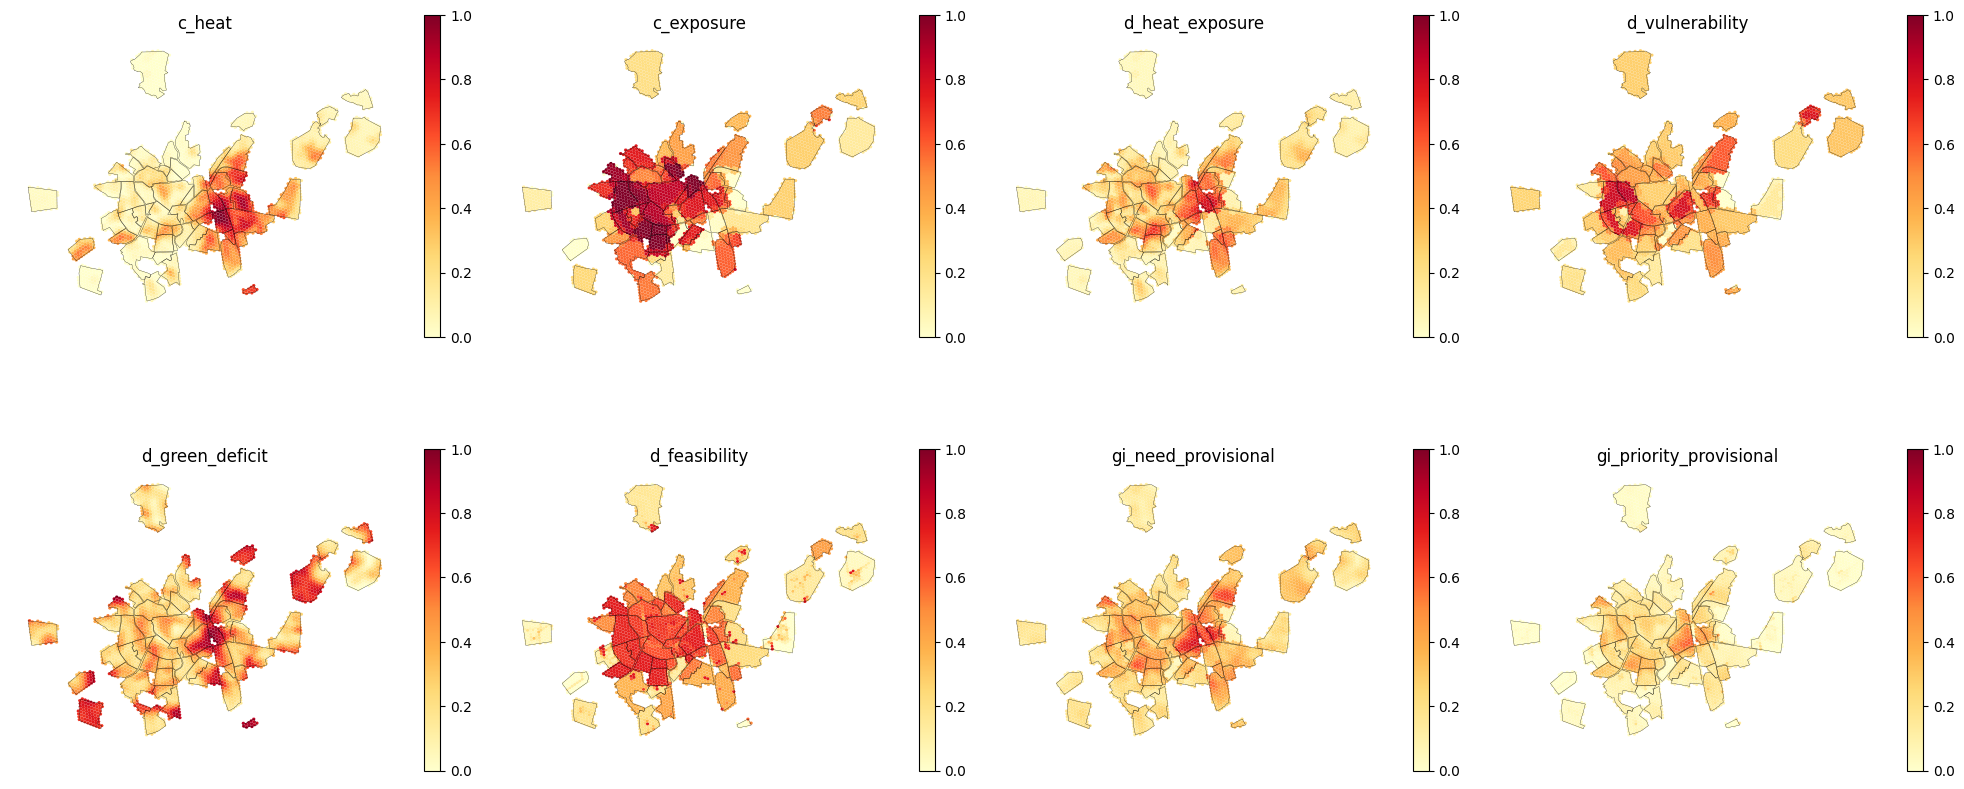

In [ ]:
show = ["c_heat", "c_exposure", "d_heat_exposure", "d_vulnerability", "d_green_deficit", "d_feasibility",
        "gi_need_provisional", "gi_priority_provisional"]
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, c in zip(axes.flat, show):
    hexes.plot(column=c, ax=ax, cmap="YlOrRd", vmin=0, vmax=1, legend=True, edgecolor="none",
               missing_kwds={"color": "lightgrey"}, legend_kwds={"shrink": 0.6})
    mz.boundary.plot(ax=ax, color="black", linewidth=0.2)
    ax.set_title(c); ax.set_axis_off()
fig.tight_layout()

## 8. Quality checks

* Population is conserved between microzones and hexes.
* Every `mu_`, `c_`, `d_` column stays within 0-1.
* Share of hexes with data per indicator (low coverage = check that input).
* Top 15 hexes by provisional priority, with their microzone, for a sanity check against local knowledge.

In [ ]:
mz_pop = mz.loc[mz.intersects(hexes.union_all()), pop_col].sum()
print(f"Residents: microzones {mz_pop:,.0f} | hexes {hexes['raw_residents'].sum():,.0f} "
      f"({hexes['raw_residents'].sum() / mz_pop:.1%})")

scored = [c for c in hexes if c.startswith(("mu_", "c_", "d_", "gi_"))]
bad = {c: (float(hexes[c].min()), float(hexes[c].max())) for c in scored
       if hexes[c].min() < -1e-9 or hexes[c].max() > 1 + 1e-9}
print("All scores within 0-1" if not bad else f"Out of range: {bad}")

cov = hexes[[c for c in hexes if c.startswith("mu_")]].notna().mean().rename("share of hexes with data")
display(cov.to_frame().style.format("{:.0%}"))

hexes.nlargest(15, "gi_priority_provisional")[["h3_index", "mz_id", "c_heat", "c_exposure", "d_vulnerability", "d_green_deficit",
                                               "d_feasibility", "gi_priority_provisional"]].round(3)

Residents: microzones 101,552 | hexes 101,485 (99.9%)
All scores within 0-1


,share of hexes with data
mu_heatwave_tmax,100%
mu_heatwave_tmin,100%
mu_lst_copernicus,100%
mu_lst_microzone,100%
mu_res_density,100%
mu_day_density,100%
mu_share_65plus,90%
mu_share_75plus,90%
mu_share_0_4,90%
mu_sensitive_facilities,100%


,h3_index,mz_id,c_heat,c_exposure,d_vulnerability,d_green_deficit,d_feasibility,gi_priority_provisional
1311,8a1e0418accffff,Mikrozóna Kosmonautů,0.693,0.772,0.799,0.897,0.750,0.605
1313,8a1e0418acdffff,Mikrozóna Kosmonautů,0.637,0.772,0.799,0.891,0.750,0.595
1315,8a1e0418aceffff,Mikrozóna Kosmonautů,0.585,0.772,0.799,0.891,0.750,0.587
1310,8a1e0418acc7fff,Mikrozóna Kosmonautů,0.586,0.772,0.799,0.867,0.750,0.581
1139,8a1e0418a52ffff,Mikrozóna Kosmonautů,0.584,0.763,0.771,0.874,0.750,0.575
1312,8a1e0418acd7fff,Mikrozóna Kosmonautů,0.526,0.772,0.799,0.876,0.750,0.573
1059,8a1e0418a197fff,Mikrozóna Kosmonautů,0.792,0.766,0.638,0.888,0.750,0.571
1062,8a1e0418a1b7fff,Mikrozóna Kosmonautů,0.723,0.766,0.638,0.918,0.750,0.569
1299,8a1e0418ac5ffff,Mikrozóna Kosmonautů,0.620,0.768,0.672,0.938,0.750,0.568
1138,8a1e0418a527fff,Mikrozóna Kosmonautů,0.464,0.763,0.771,0.876,0.750,0.554


## 9. Validation with residents' summer heat map

The summer heat perception map (2020-21, 579 respondents) is **independent** of every index input, so it is used
only to check the result, never as an input.

* **Marks:** `a` = places that feel **uncomfortable** on hot days, `b` = **comfortable** (the question texts in the
  file look swapped; the answers make the meaning clear: `a` is mostly "very hot", "I only walk in the shade",
  "I avoid this place").
* **Per hex:** a point counts 1 in its hex; a drawn area counts 1 in total, split over the hexes it covers by area.
  Areas over `max_polygon_ha` are left out as too vague; broken shapes are repaired.
* **Perceived heat score** = uncomfortable / (uncomfortable + comfortable), only where a hex has at least
  `min_marks` marks. Using a ratio removes the bias that more people respond in the centre.
* **Comparison:** Spearman rank correlation with the index layers (the index is relative, so ranks are compared,
  not degrees), and the **hit rate**: the share of uncomfortable marks that fall in the top 20% of hexes by GI need.
* **Time gap:** the survey (2020-21) is older than the heat data (2026). Heat hotspots are driven by sealed ground and
  missing trees, which change slowly, so the spatial pattern is comparable. Hexes that were construction sites in
  Urban Atlas 2021 are left out, because those places changed.
* **Privacy:** the file contains IP addresses, user IDs and demographics. Only per-hex counts are kept; no personal
  attribute is exported.

Validation: residents' summer heat map
  + summer heat perception map: 2091 features from pocitova-teplotni-mapa-olomouce-2.geojson
    1 marks with broken coordinates left out
    668 points, 1295 areas used, 127 areas over 50 ha left out
    114 hexes with at least 3 marks used for the comparison


,layer,column,expected sign,Spearman r,significant (p<0.05),direction as expected,hexes
0,Heat (2026 heatwave + thermal),c_heat,+,0.66,yes,yes,114
1,Heatwave max. temperature,raw_heatwave_tmax,+,0.37,yes,yes,114
2,Sealed ground,raw_sealing,+,0.70,yes,yes,114
3,Tree cover,raw_tree_cover,-,-0.81,yes,yes,114
4,Vegetation share (NDVI),raw_vegetation_share,-,-0.74,yes,yes,114
5,Accessible green share,raw_green_share,-,-0.76,yes,yes,114
6,Lack of green (dimension),d_green_deficit,+,0.78,yes,yes,114
7,GI need (final result),gi_need_provisional,+,0.73,yes,yes,114



    Top 20% of hexes by GI need hold 56% of residents' UNCOMFORTABLE marks and 7% of COMFORTABLE marks (random would be about 20% each).

    Suggestions at uncomfortable places (533 with text), mentions of:


,mentions
trees,287
greenery,185
shade,89
water,81
less concrete/asphalt,42
trees + avenue,13
benches,9
air conditioning,5


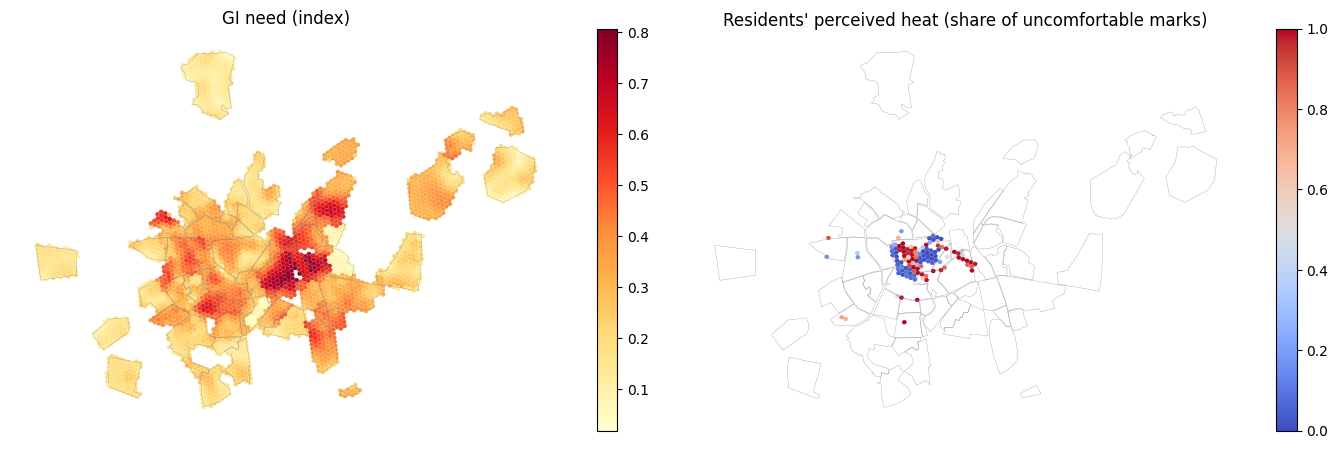

In [ ]:
print("Validation: residents' summer heat map")
from scipy.stats import spearmanr
import shapely
ps = CONFIG["perception_heat"]
pm = read_layer(ps, "summer heat perception map")
val_cols = []
if pm is not None:
    pm = pm[[ps["type_col"], ps["comment_col"], "geometry"]].copy()          # drop all personal attributes
    finite = np.isfinite(pm.geometry.bounds.to_numpy()).all(axis=1)          # drop shapes with broken coordinates
    if (~finite).any():
        print(f"    {int((~finite).sum())} marks with broken coordinates left out")
    pm = pm[finite]
    pm["geometry"] = shapely.make_valid(pm.geometry.values)
    pm = pm[~pm.geometry.is_empty]
    pm["_kind"] = pm[ps["type_col"]].map({ps["uncomfortable"]: "uncomf", ps["comfortable"]: "comf"})
    pm = pm.dropna(subset=["_kind"]).reset_index(drop=True)
    pm["_mark"] = np.arange(len(pm))
    is_pt = pm.geom_type.isin(["Point", "MultiPoint"])
    polys = pm[~is_pt].explode(index_parts=False)
    polys = polys[polys.geom_type.isin(["Polygon", "MultiPolygon"])]
    big = polys.groupby("_mark").geometry.apply(lambda s: s.area.sum()) > ps["max_polygon_ha"] * 1e4
    polys = polys[~polys["_mark"].isin(big[big].index)]
    print(f"    {int(is_pt.sum())} points, {polys['_mark'].nunique()} areas used, {int(big.sum())} areas over "
          f"{ps['max_polygon_ha']} ha left out")

    weights = {k: pd.Series(0.0, index=hexes["h3_index"]) for k in ["uncomf", "comf"]}
    pts = pm[is_pt]
    if len(pts):
        p4326 = pts.to_crs(4326)
        cells = [h3.latlng_to_cell(g.y, g.x, CONFIG["h3_res"]) for g in p4326.geometry.representative_point()]
        for k, c in zip(pts["_kind"], cells):
            if c in weights[k].index:
                weights[k][c] += 1
    if len(polys):
        pp = gpd.overlay(polys[["_mark", "_kind", "geometry"]], hexes[["h3_index", "geometry"]], how="intersection",
                         keep_geom_type=True)
        tot = polys.assign(_a=polys.area).groupby("_mark")["_a"].sum()
        pp["_w"] = pp.area / pp["_mark"].map(tot)
        for k, grp in pp.groupby("_kind"):
            weights[k] = weights[k].add(grp.groupby("h3_index")["_w"].sum(), fill_value=0)
    hexes["val_uncomfortable"] = hexes["h3_index"].map(weights["uncomf"]).fillna(0)
    hexes["val_comfortable"] = hexes["h3_index"].map(weights["comf"]).fillna(0)
    n = hexes["val_uncomfortable"] + hexes["val_comfortable"]
    hexes["val_perceived_heat"] = np.where(n >= ps["min_marks"], hexes["val_uncomfortable"] / n.replace(0, np.nan), np.nan)
    val_cols = ["val_uncomfortable", "val_comfortable", "val_perceived_heat"]

    # leave out places that were changing around the survey time (construction sites in Urban Atlas 2021)
    ok = hexes["val_perceived_heat"].notna()
    if ua is not None:
        cons = ua[ua["_code"] == "13300"]
        if len(cons):
            ok &= share_to_hex(cons, hexes).fillna(0) < 0.1
    print(f"    {int(ok.sum())} hexes with at least {ps['min_marks']} marks used for the comparison")

    rows = []
    for col, label, expect in [("c_heat", "Heat (2026 heatwave + thermal)", "+"),
                               ("raw_heatwave_tmax", "Heatwave max. temperature", "+"),
                               ("raw_sealing", "Sealed ground", "+"),
                               ("raw_tree_cover", "Tree cover", "-"),
                               ("raw_vegetation_share", "Vegetation share (NDVI)", "-"),
                               ("raw_green_share", "Accessible green share", "-"),
                               ("d_green_deficit", "Lack of green (dimension)", "+"),
                               ("gi_need_provisional", "GI need (final result)", "+")]:
        if col in hexes:
            sub = hexes.loc[ok, [col, "val_perceived_heat"]].dropna()
            if len(sub) >= 10:
                r, p = spearmanr(sub[col], sub["val_perceived_heat"])
                agrees = (r > 0) == (expect == "+")
                rows.append((label, col, expect, round(r, 2), "yes" if p < 0.05 else "no", "yes" if agrees else "NO", len(sub)))
    VALIDATION = pd.DataFrame(rows, columns=["layer", "column", "expected sign", "Spearman r", "significant (p<0.05)",
                                             "direction as expected", "hexes"])
    display(VALIDATION)

    top = hexes["gi_need_provisional"] >= hexes["gi_need_provisional"].quantile(1 - ps["top_share"])
    hit_u = hexes.loc[top, "val_uncomfortable"].sum() / max(hexes["val_uncomfortable"].sum(), 1e-9)
    hit_c = hexes.loc[top, "val_comfortable"].sum() / max(hexes["val_comfortable"].sum(), 1e-9)
    HIT = {"top_share": ps["top_share"], "uncomfortable_in_top": round(hit_u, 3), "comfortable_in_top": round(hit_c, 3)}
    print(f"\n    Top {ps['top_share']:.0%} of hexes by GI need hold {hit_u:.0%} of residents' UNCOMFORTABLE marks "
          f"and {hit_c:.0%} of COMFORTABLE marks (random would be about {ps['top_share']:.0%} each).")

    # what residents ask for at uncomfortable places
    txt = pm.loc[pm["_kind"] == "uncomf", ps["comment_col"]].fillna("").str.lower()
    keys = {"trees": "strom", "greenery": "zele", "shade": "stín|stin", "water": "vod|fontán|kašn", "benches": "lavič|lavic",
            "trees + avenue": "alej|stromořad", "less concrete/asphalt": "beton|asfalt|dlažb", "air conditioning": "klimatiz"}
    KEYWORDS = pd.Series({k: int(txt.str.contains(v, regex=True).sum()) for k, v in keys.items()}).sort_values(ascending=False)
    print(f"\n    Suggestions at uncomfortable places ({int((txt.str.len() > 0).sum())} with text), mentions of:")
    display(KEYWORDS.to_frame("mentions"))

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    hexes.plot(column="gi_need_provisional", ax=axes[0], cmap="YlOrRd", legend=True, edgecolor="none", legend_kwds={"shrink": 0.6})
    hexes[ok].plot(column="val_perceived_heat", ax=axes[1], cmap="coolwarm", vmin=0, vmax=1, legend=True, edgecolor="none",
                   legend_kwds={"shrink": 0.6})
    for ax, t in zip(axes, ["GI need (index)", "Residents' perceived heat (share of uncomfortable marks)"]):
        mz.boundary.plot(ax=ax, color="grey", linewidth=0.2); ax.set_title(t); ax.set_axis_off()
    fig.tight_layout()

In [ ]:
for col in ["raw_heatwave_tmax", "raw_heatwave_tmin", "raw_lst_microzone", "raw_sealing", "raw_tree_cover", "raw_vegetation_share"]:
    if col in hexes:
        sub = hexes.loc[ok, [col, "val_perceived_heat"]].dropna()
        r, p = spearmanr(sub[col], sub["val_perceived_heat"])
        print(f"{col:22s} r = {r:+.2f}   p = {p:.3f}")

raw_heatwave_tmax      r = +0.37   p = 0.000
raw_heatwave_tmin      r = +0.34   p = 0.000
raw_lst_microzone      r = +0.28   p = 0.003
raw_sealing            r = +0.70   p = 0.000
raw_tree_cover         r = -0.81   p = 0.000
raw_vegetation_share   r = -0.74   p = 0.000


## 10. Export

| File | Content | Use |
|---|---|---|
| `olomouc_gi_h3_r{res}.csv` | `h3_index` + all `raw_`, `mu_`, `c_`, `d_`, `gi_` columns | Web portal (deck.gl `H3HexagonLayer` reads `h3_index` directly) |
| `olomouc_gi_h3_r{res}.gpkg` | same, with hexagon polygons (EPSG:5514) | QGIS / ArcGIS |
| `olomouc_gi_h3_r{res}.geojson` | same, WGS84 | Leaflet / MapLibre |
| `olomouc_gi_h3_r{res}_metadata.json` | config, resolved thresholds, weights, run time | Documentation and reproducibility |

In [ ]:
res = CONFIG["h3_res"]
stem = OUT / f"olomouc_gi_h3_r{res}"
keep = ["h3_index", "mz_id", "coverage", "area_ha"] + (["h3_parent_r9"] if "h3_parent_r9" in hexes else []) + [c for c in hexes if c.startswith(("raw_", "mu_", "c_", "d_", "gi_", "val_"))]
out = hexes[keep + ["geometry"]]

out.drop(columns="geometry").round(5).to_csv(f"{stem}.csv", index=False)
out.to_file(f"{stem}.gpkg", driver="GPKG", layer="gi_h3")
out.to_crs(4326).to_file(f"{stem}.geojson", driver="GeoJSON")

meta = {
    "created": datetime.datetime.now().isoformat(timespec="seconds"),
    "h3_resolution": res,
    "hex_count": int(len(hexes)),
    "indicators": thresholds_used,
    "component_weights": {k: v for k, v in components.items()},
    "dimension_weights": {"green_deficit": {"c_green_supply": 0.5, "c_green_access": 0.5},
                          "feasibility": FEAS_WEIGHTS, "feasibility_agg": CONFIG["feasibility_agg"],
                          "opportunity_agg": CONFIG["opportunity_agg"],
                          "need": NEED_WEIGHTS},
    "heat_hazard_share_a": CONFIG["heat_hazard_share_a"], "day_weight": CONFIG["day_weight"],
    "validation": ({"spearman": VALIDATION.to_dict("records"), "hit_rate": HIT} if "VALIDATION" in globals() else None),
    "config": json.loads(json.dumps(CONFIG, default=str)),
}
Path(f"{stem}_metadata.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False, default=str))
for ext in [".csv", ".gpkg", ".geojson", "_metadata.json"]:
    print("written", f"{stem}{ext}")

written /content/drive/MyDrive/hackathon-upol/output/olomouc_gi_h3_r10.csv
written /content/drive/MyDrive/hackathon-upol/output/olomouc_gi_h3_r10.gpkg
written /content/drive/MyDrive/hackathon-upol/output/olomouc_gi_h3_r10.geojson
written /content/drive/MyDrive/hackathon-upol/output/olomouc_gi_h3_r10_metadata.json


## 11. Status and next steps

**Done**
* Heat: heatwave Tmax/Tmin (Citiq, summer 2026) and microzone thermal mean, weighted 15/45/40 after validation.
* Exposure: residents placed in residential buildings (Urban Atlas mask). Vulnerability: ages 65+, 75+, 0-4 and
  sensitive facilities.
* Green deficit: Urban Atlas green, Copernicus tree cover and imperviousness, network distance to green (OSM streets,
  straight-line x 1.3 where streets do not connect).
* Feasibility: brownfields, public buildings, vacant land, parking, cycle paths, streets; constraints (rail, fast roads, airport, water).
* Validation against residents' summer heat map (section 9).

**Out of scope:** flood risk (the index is heat-focused).

**Possible next steps**
1. **Sensitivity test:** rerun with weights and thresholds changed by +/- 20% and keep the hexes that stay in the
   top 10% of GI need in most runs.
2. **Landsat surface temperature** (30 m, summer 2026) in the `lst_raster` slot for local heat detail.
3. **Roads with footpaths**, clipped to the microzones plus a 500 m buffer, for fully network-based walking distance.
4. **Daytime population** (Vodafone) for daytime exposure.
5. **Resolution 10 drill-down** once heat and population data are finer than the microzones.